In [1]:
import numpy as np
import xarray as xr
import rioxarray as rxr
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import glob
import pickle
import seaborn as sns
from datetime import datetime, timedelta
import matplotlib.ticker as mticker
from scipy import stats
from statsmodels.nonparametric.kde import KDEUnivariate
from matplotlib.colors import Normalize
from scipy.ndimage import gaussian_filter
from PIL import Image

Notes from spatial analysis section:

LST histogram, cloud coverage and when maybe, 
One by histogram, each city has a colored line, statistical outliers

All data analysis. General properties of the dataset

In [2]:
# This is the root directory where the dataset is stored
dataset_root = '/glade/derecho/scratch/jstarfeldt/uhminicubes'

In [3]:
# Creates a sorted list of cities in the dataset
cities = [
    'Jacksonville', 'DMV', 'NYC', 'Phoenix', 'Miami', 'Chicago', 'Denver', 'Seattle', 'San_Francisco', 'Los_Angeles', 'Atlanta', 'Toronto',
    'Mexico_City', 'Las_Vegas', 'Salt_Lake_City', 'Dallas', 'Houston', 'New_Orleans', 'St_Louis', 'Minneapolis',
    'Charlotte', 'Philadelphia', 'San_Diego', 'San_Juan', 'Montreal', 'Guadalajara', 'Monterrey', 'Cancun', 'Billings', 'Guatemala_City',
    'San_Jose', 'Havana', 'Santo_Domingo', 'Tegucigalpa', 'Managua', 'Panama_City', 'Bogota', 'Lima', 'Quito', 'Santiago', 'Buenos_Aires',
    'Sao_Paulo', 'Manaus', 'Punta_Arenas', 'La_Paz', 'Montevideo', 'Brasilia', 'Caracas'
]
cities = sorted(cities)

In [4]:
# Dictionary mapping city names or abbreviations to full
# city and country information
city_str_dict = {
    'Atlanta': 'Atlanta, Georgia, USA',
    'Billings': 'Billings, Montana, USA',
    'Bogota': 'Bogota, Colombia',
    'Brasilia': 'Brasilia, Brazil',
    'Buenos_Aires': 'Buenos Aires, Argentina',
    'Cancun': 'Cancun, Mexico',
    'Caracas': 'Caracas, Venezuela',
    'Charlotte': 'Charlotte, North \nCarolina, USA',
    'Chicago': 'Chicago, Illinois, USA',
    'Dallas': 'Dallas, Texas, USA and \nFort Worth, Texas, USA',
    'Denver': 'Denver, Colorado, USA',
    'Guadalajara': 'Guadalajara, Mexico',
    'Guatemala_City': 'Guatemala City, \nGuatemala',
    'Havana': 'Havana, Cuba',
    'Houston': 'Houston, Texas, USA',
    'Jacksonville': 'Jacksonville, Florida, USA',
    'La_Paz': 'La Paz, Bolivia',
    'Las_Vegas': 'Las Vegas, \nNevada, USA',
    'Lima': 'Lima, Peru',
    'Los_Angeles': 'Los Angeles, \nCalifornia, USA',
    'Managua': 'Managua, Nicaragua',
    'Manaus': 'Manaus, Brazil',
    'Mexico_City': 'Mexico City, Mexico',
    'Miami': 'Miami, Florida, USA',
    'Minneapolis': 'Minneapolis, \nMinnesota, USA',
    'Monterrey': 'Monterrey, Mexico',
    'Montevideo': 'Montevideo, Uruguay',
    'Montreal': 'Montreal, \nQuebec, Canada',
    'New_Orleans': 'New Orleans, \nLouisiana, USA',
    'NYC': 'New York City, \nNew York, USA',
    'Panama_City': 'Panama City, Panama',
    'Philadelphia': 'Philadelphia, \nPennsylvania, USA',
    'Phoenix': 'Phoenix, Arizona, USA',
    'Punta_Arenas': 'Punta Arenas, Chile',
    'Quito': 'Quito, Ecuador',
    'Salt_Lake_City': 'Salt Lake City, \nUtah, USA',
    'San_Diego': 'San Diego, California, USA \nand Tijuana, Mexico',
    'San_Francisco': 'San Francisco, \nCalifornia, USA',
    'San_Jose': 'San Jose, Costa Rica',
    'San_Juan': 'San Juan, Puerto Rico',
    'Santiago': 'Santiago, Chile',
    'Santo_Domingo': 'Santo Domingo, \nDominican Republic',
    'Sao_Paulo': 'Sao Paulo, Brazil',
    'Seattle': 'Seattle, \nWashington, USA',
    'St_Louis': 'St Louis, Missouri, USA',
    'Tegucigalpa': 'Tegucigalpa, Honduras',
    'Toronto': 'Toronto, Ontario, Canada',
    'DMV': 'Washington, DC, USA and \nBaltimore, Maryland, USA'
}

In [5]:
city_ICAO_codes = {
    'Atlanta': 'KATL',
    'Billings': 'KBIL',
    'Bogota': 'SKBO',
    'Brasilia': 'SBBR',
    'Buenos_Aires': 'SAEZ',
    'Cancun': 'MMUN',
    'Caracas': 'SVMI',
    'Charlotte': 'KCLT',
    'Chicago': 'KORD',
    'Dallas': 'KDFW',
    'Denver': 'KDEN',
    'Guadalajara': 'MMGL',
    'Guatemala_City': 'MGGT',
    'Havana': 'MUHA',
    'Houston': 'KIAH',
    'Jacksonville': 'KJAX',
    'La_Paz': 'SLLP',
    'Las_Vegas': 'KLAS',
    'Lima': 'SPJC',
    'Los_Angeles': 'KLAX',
    'Managua': 'MNMG',
    'Manaus': 'SBEG',
    'Mexico_City': 'MMMX',
    'Miami': 'KMIA',
    'Minneapolis': 'KMSP',
    'Monterrey': 'MMMY',
    'Montevideo': 'SUMU',
    'Montreal': 'CYUL',
    'New_Orleans': 'KMSY',
    'NYC': 'KJFK',
    'Panama_City': 'MPTO',
    'Philadelphia': 'KPHL',
    'Phoenix': 'KPHX',
    'Punta_Arenas': 'SCCI',
    'Quito': 'SEQM',
    'Salt_Lake_City': 'KSLC',
    'San_Diego': 'KSAN',
    'San_Francisco': 'KSFO',
    'San_Jose': 'MROC',
    'San_Juan': 'TJSJ',
    'Santiago': 'SCEL',
    'Santo_Domingo': 'MDSD',
    'Sao_Paulo': 'SBGR',
    'Seattle': 'KSEA',
    'St_Louis': 'KSTL',
    'Tegucigalpa': 'MHTG',
    'Toronto': 'CYYZ',
    'DMV': 'KBWI'
}

In [6]:
"""
Export coordinates for each urban area
KEY: [utm zone, T/F for Northern Hemisphere]
"""
proj_zone = {
    'DMV':[18, True], 'NYC':[18, True], 'Phoenix':[12, True], 'Miami':[17, True], 'Chicago':[16, True], 'Denver':[13, True],
    'Seattle':[10, True], 'San_Francisco':[10, True], 'Los_Angeles':[11, True], 'Atlanta':[16, True], 'Toronto':[17, True],
    'Mexico_City':[14, True], 'Las_Vegas':[11, True], 'Salt_Lake_City':[12, True], 'Dallas':[14, True], 'Houston':[15, True],
    'New_Orleans':[15, True], 'St_Louis':[15, True], 'Minneapolis':[15, True], 'Jacksonville':[17, True], 'Charlotte':[17, True],
    'Philadelphia':[18, True], 'San_Diego':[11, True], 'San_Juan':[19, True], 'Montreal':[18, True], 'Guadalajara':[13, True],
    'Monterrey':[14, True], 'Cancun':[16, True], 'Billings':[12, True], 'Guatemala_City':[15, True], 'San_Jose':[16, True],
    'Havana':[17, True], 'Santo_Domingo':[19, True], 'Tegucigalpa':[16, True], 'Managua':[16, True], 'Panama_City':[17, True],
    'Bogota':[18, True], 'Lima':[18, False], 'Quito':[17, True], 'Santiago':[19, False], 'Buenos_Aires':[21, False],
    'Sao_Paulo':[23, False], 'Manaus':[20, False], 'Punta_Arenas':[19, False],
    'La_Paz':[19, False], 'Montevideo':[21, False], 'Brasilia':[22, False], 'Caracas':[19, True]
}

In [7]:
"""
Returns an integer as a str, adding a zero in front if it is a single digit.

Attributes:
    num (int): Integer to turn into a string.
"""
def stringify(num):
    if num >= 0 and num < 10:
        return f'0{num}'
    else:
        return str(num)

In [8]:
def round_to_nearest_10_minutes(dt):
    """
    Rounds a datetime object to the nearest 10 minutes.

    Args:
    dt (datetime object): Datetime to round

    Returns:
    rounded_dt (datetime object): Rounded datetime
    """
    # Calculate the remainder when minutes are divided by 10
    remainder_minutes = dt.minute % 10

    # Determine whether to round up or down
    if remainder_minutes >= 5:
        # Round up: add minutes to reach the next 10-minute interval
        minutes_to_add = 10 - remainder_minutes
        rounded_dt = dt + timedelta(minutes=minutes_to_add)
    else:
        # Round down: subtract minutes to reach the previous 10-minute interval
        minutes_to_subtract = remainder_minutes
        rounded_dt = dt - timedelta(minutes=minutes_to_subtract)

    return rounded_dt

In [9]:
# Dictionaries for storing file datetimes from the dataset
date_dict = {string: [] for string in cities}  # Landsat/Sentinel-1 datetimes
date_str_dict = {string: [] for string in cities}  # Landsat/Sentinel-1 datetime strings
GOES_date_dict = {string: [] for string in cities}  # GOES datetimes at Landsat file datetimes

In [10]:
def check_GOES_file_exists(dt, city):
    """
    Checks if a GOES file exists. Used as a secondary function to
    round_to_nearest_10_minutes to check if the rounded datetime has
    a corresponding file.

    Args:
    dt (datetime object): Datetime of the GOES file to check for

    Returns:
    exists (boolean): Whether the file exists or not
    """
    dt_str = dt.strftime("%Y%m%d%H%M")
    file_list = glob.glob(f'{dataset_root}/lresgrid/{str(dt.year)}/{stringify(dt.month)}/{city_ICAO_codes[city]}/*')
    exists = f'{dataset_root}/lresgrid/{str(dt.year)}/{stringify(dt.month)}/{city_ICAO_codes[city]}/lresgrid_{city_ICAO_codes[city]}_{dt_str}.nc' in file_list

    return exists

In [11]:
def file_date_sort(file_str):
    """
    Returns the datetime portion of a file name.
    Used to sort file directories.

    Args:
    file_str (str): File string to sort

    Returns:
    (str): Datetime portion of the file string
    """
    return file_str.split('_')[-1].split('.')[0]

In [12]:
city_Landsat_lists = {}

for city in cities:
    city_list = []
    for year_dir in sorted(glob.glob(f'{dataset_root}/hresgrid/2*')):
        for month_dir in sorted(glob.glob(f'{year_dir}/*')):
            city_list.extend(sorted(glob.glob(f'{month_dir}/{city_ICAO_codes[city]}/*')))
    city_Landsat_lists[city] = city_list

In [13]:
# For each processed Landsat file, adds the closest GOES file in time
# to the GOES_date_dict object, if it exists
format_string = "%Y%m%d%H%M"

for city in cities:
    city_list = city_Landsat_lists[city]

    for file in city_list:
        dt_str = file.split('_')[-1].split('.')[0]
        dt = datetime.strptime(dt_str, format_string)
        date_dict[city].append(dt)
        date_str_dict[city].append(dt_str[:8])
        rounded_dt = round_to_nearest_10_minutes(dt)
        if check_GOES_file_exists(rounded_dt, city):  # Only add to list if the time has a GOES file
            GOES_date_dict[city].append(rounded_dt)

## Satellite Temperature Comparison

In [14]:
# Stores the average Landsat LST from each Landsat file
# into the city_LST_dict dictionary
city_LST_dict = {string: [] for string in cities}
city_list = []

for city in cities:
    city_list = city_Landsat_lists[city]

    for file in city_list:
        data = xr.open_dataset(file)['Landsat_LST'].values
        city_LST_dict[city].append(np.nanmean(data))

# Save mean LST data to a pickle
with open('/glade/derecho/scratch/jstarfeldt/data_analysis/all_LSTs.pkl', 'wb') as file:
    pickle.dump(city_LST_dict, file)

/glade/derecho/scratch/jstarfeldt/tmp/ipykernel_26975/2372752923.py:11: RuntimeWarning: Mean of empty slice
  city_LST_dict[city].append(np.nanmean(data))


In [15]:
# Load mean LST pickle
with open('/glade/derecho/scratch/jstarfeldt/data_analysis/all_LSTs.pkl', 'rb') as file:
    city_LST_dict = pickle.load(file)

In [16]:
# Sort the dictionary by the median of its array values
sorted_data = dict(sorted(city_LST_dict.items(), key=lambda item: np.nanmedian(item[1]), reverse=True))

In [17]:
# Same as the prior city_str_dict but more cities are spread
# over two lines to make room for adding numbers to subplot titles
ordered_city_str_dict = {
    'Atlanta': 'Atlanta, \nGeorgia, USA',
    'Billings': 'Billings, \nMontana, USA',
    'Bogota': 'Bogota, Colombia',
    'Brasilia': 'Brasilia, Brazil',
    'Buenos_Aires': 'Buenos Aires, \nArgentina',
    'Cancun': 'Cancun, Mexico',
    'Caracas': 'Caracas, Venezuela',
    'Charlotte': 'Charlotte, North \nCarolina, USA',
    'Chicago': 'Chicago, \nIllinois, USA',
    'Dallas': 'Dallas, Texas, USA and \nFort Worth, Texas, USA',
    'Denver': 'Denver, \nColorado, USA',
    'Guadalajara': 'Guadalajara, Mexico',
    'Guatemala_City': 'Guatemala City, \nGuatemala',
    'Havana': 'Havana, Cuba',
    'Houston': 'Houston, Texas, USA',
    'Jacksonville': 'Jacksonville, \nFlorida, USA',
    'La_Paz': 'La Paz, Bolivia',
    'Las_Vegas': 'Las Vegas, \nNevada, USA',
    'Lima': 'Lima, Peru',
    'Los_Angeles': 'Los Angeles, \nCalifornia, USA',
    'Managua': 'Managua, \nNicaragua',
    'Manaus': 'Manaus, Brazil',
    'Mexico_City': 'Mexico City, Mexico',
    'Miami': 'Miami, Florida, USA',
    'Minneapolis': 'Minneapolis, \nMinnesota, USA',
    'Monterrey': 'Monterrey, Mexico',
    'Montevideo': 'Montevideo, \nUruguay',
    'Montreal': 'Montreal, \nQuebec, Canada',
    'New_Orleans': 'New Orleans, \nLouisiana, USA',
    'NYC': 'New York City, \nNew York, USA',
    'Panama_City': 'Panama City, \nPanama',
    'Philadelphia': 'Philadelphia, \nPennsylvania, USA',
    'Phoenix': 'Phoenix, \nArizona, USA',
    'Punta_Arenas': 'Punta Arenas, \nChile',
    'Quito': 'Quito, Ecuador',
    'Salt_Lake_City': 'Salt Lake City, \nUtah, USA',
    'San_Diego': 'San Diego, California, \nUSA and Tijuana, Mexico',
    'San_Francisco': 'San Francisco, \nCalifornia, USA',
    'San_Jose': 'San Jose, \nCosta Rica',
    'San_Juan': 'San Juan, \nPuerto Rico',
    'Santiago': 'Santiago, Chile',
    'Santo_Domingo': 'Santo Domingo, \nDominican Republic',
    'Sao_Paulo': 'Sao Paulo, Brazil',
    'Seattle': 'Seattle, \nWashington, USA',
    'St_Louis': 'St Louis, \nMissouri, USA',
    'Tegucigalpa': 'Tegucigalpa, Honduras',
    'Toronto': 'Toronto, \nOntario, Canada',
    'DMV': 'Washington, DC, USA and \nBaltimore, Maryland, USA'
}

0
6
12
18
24
30
36
42


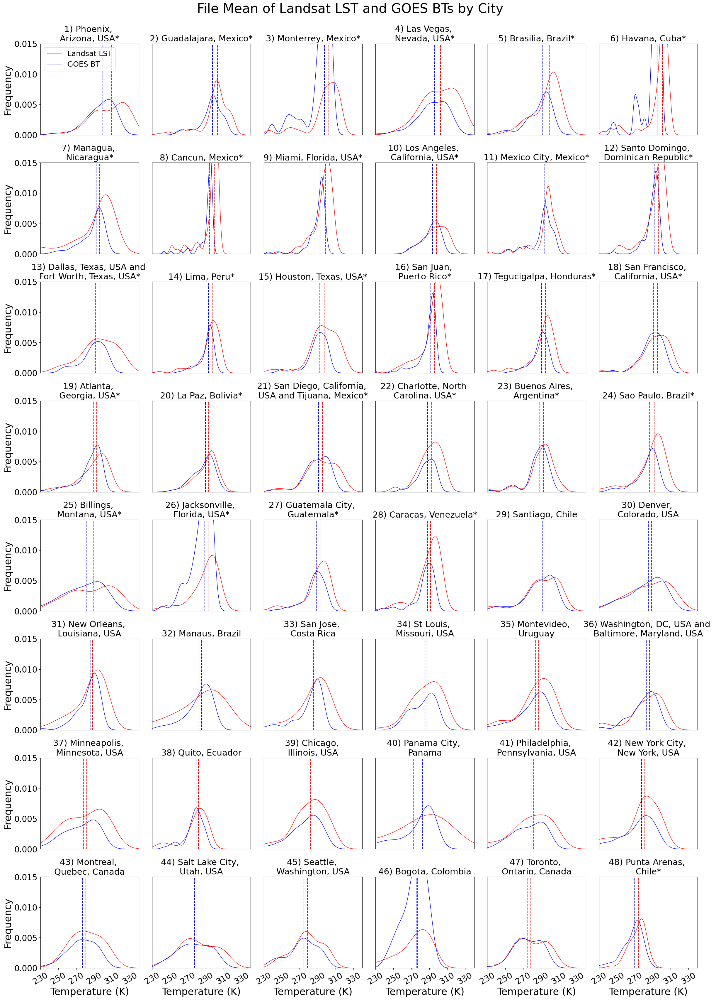

In [18]:
# Get the list of city names, sorted by LST
sorted_cities = list(sorted_data.keys())

# Set up plot axes and general variables
fig, axs = plt.subplots(8, 6)
fig.set_size_inches(24, 34)
plt.setp(plt.gcf().get_axes(), xticks=[], yticks=[])
plt.subplots_adjust(wspace=-0.2)
colors = cm.jet(np.linspace(0, 1, 48))

i = 0
for row in axs:
    print(i)
    for ax in row:
        city = sorted_cities[i]
        # Fit a PDF to the average Landsat LST data for this city
        Landsat_data = sorted_data[city]
        Landsat_data = np.array(Landsat_data)[~np.isnan(Landsat_data)]
        LST_pdf = KDEUnivariate(Landsat_data)
        LST_pdf.fit()
        LST = LST_pdf.density/np.sum(LST_pdf.density)

        # Fit a PDF to the average GOES brightness temperature (BT) data for this city
        GOES_data = np.zeros(len(GOES_date_dict[city]))
        j = 0
        for dt in GOES_date_dict[city]:
            dt_str = dt.strftime("%Y%m%d%H%M")
            data = xr.open_dataset(f'{dataset_root}/lresgrid/{str(dt.year)}/{stringify(dt.month)}/{city_ICAO_codes[city]}/lresgrid_{city_ICAO_codes[city]}_{dt_str}.nc')
            GOES_data[j] = np.nanmean(data[list(data.data_vars)[:4]].to_dataarray()[1])
            j += 1

        GOES_data = GOES_data.flatten()
        GOES_pdf = KDEUnivariate(GOES_data)
        GOES_pdf.fit()
        BT = GOES_pdf.density/np.sum(GOES_pdf.density)

        # Calculate Mann-Whitney test for equivalence of distribution
        p_value = stats.mannwhitneyu(Landsat_data, GOES_data, nan_policy='omit').pvalue

        # Plot the PDFs
        ax.plot(LST_pdf.support, LST, linewidth=1, color='red', label='Landsat LST')
        ax.plot(GOES_pdf.support, BT, linewidth=1, color='b', label='GOES BT')
        ax.set_xticks([])
        ax.set_ylim(bottom=0, top=0.015)
        ax.set_xlim(left=230, right=340)
        ax.set_yticks([])

        # Plot vertical lines at the middle point of each distribution
        LST_middle = LST_pdf.support[np.where(LST_pdf.cdf >= 0.5)[0][0]]
        GOES_middle = GOES_pdf.support[np.where(GOES_pdf.cdf >= 0.5)[0][0]]
        ax.axvline(x=LST_middle, color='red', linestyle='--')
        ax.axvline(x=GOES_middle, color='b', linestyle='--')

        # Set axis ticks for the left and bottom edges
        if i % 6 == 0: # First in row
            ax.set_ylabel('Frequency', fontsize=24)
            ax.set_yticks(np.arange(0, 0.016, 0.005))
            ax.tick_params(axis='y', labelsize=20)
        if i >= 42: # Last row
            ax.set_xlabel('Temperature (K)', fontsize=24)
            ax.set_xticks(np.arange(230, 341, 20), labels=np.arange(230, 341, 20), rotation=30)
            ax.tick_params(axis='x', labelsize=20)

        # Denote if the statistical test result is significant
        if p_value < 0.05:
            ax.set_title(f'{i+1}) {ordered_city_str_dict[city]}*', fontsize=21)
        else:
            ax.set_title(f'{i+1}) {ordered_city_str_dict[city]}', fontsize=21)
        i += 1

# Add a legend
handles, labels = axs[0, 0].get_legend_handles_labels()
axs[0, 0].legend(handles, labels, fontsize=18, loc='upper left', ncols=1)

# Add a title and save the figure
plt.suptitle('File Mean of Landsat LST and GOES BTs by City', y=1.001, fontsize=32)
plt.tight_layout()
fig.savefig('/glade/derecho/scratch/jstarfeldt/data_analysis/plots/temps_comparison_pdfs.pdf', transparent=True, bbox_inches='tight')

0
2


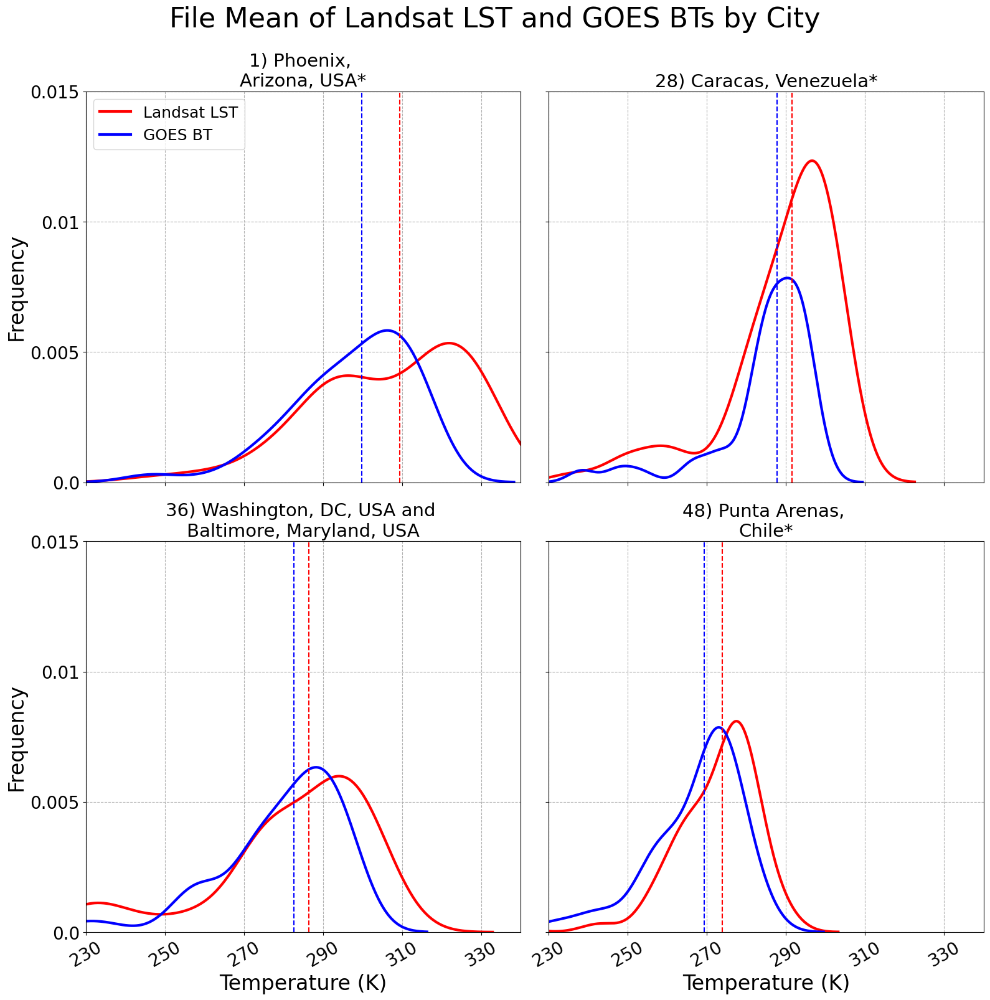

In [17]:
# Get the list of city names, sorted by LST
sorted_cities = list(sorted_data.keys())

# Set up plot axes and general variables
fig, axs = plt.subplots(2, 2)
fig.set_size_inches(16, 16)
plt.setp(plt.gcf().get_axes(), xticks=[], yticks=[])
colors = cm.jet(np.linspace(0, 1, 48))

i = 0
for row in axs:
    print(i)
    for ax in row:
        if i == 0:
            city = 'Phoenix'
            order = 1
        elif i == 1:
            city = 'Caracas'
            order = 28
        elif i == 2:
            city = 'DMV'
            order = 36
        else:
            city = 'Punta_Arenas'
            order = 48

        # Fit a PDF to the average Landsat LST data for this city
        Landsat_data = sorted_data[city]
        Landsat_data = np.array(Landsat_data)[~np.isnan(Landsat_data)]
        LST_pdf = KDEUnivariate(Landsat_data)
        LST_pdf.fit()
        LST = LST_pdf.density/np.sum(LST_pdf.density)

        # Fit a PDF to the average GOES brightness temperature (BT) data for this city
        GOES_data = np.zeros(len(GOES_date_dict[city]))
        j = 0
        for dt in GOES_date_dict[city]:
            dt_str = dt.strftime("%Y%m%d%H%M")
            data = xr.open_dataset(f'{dataset_root}/lresgrid/{str(dt.year)}/{stringify(dt.month)}/{city_ICAO_codes[city]}/lresgrid_{city_ICAO_codes[city]}_{dt_str}.nc')
            GOES_data[j] = np.nanmean(data[list(data.data_vars)[:4]].to_dataarray()[1])
            j += 1

        GOES_data = GOES_data.flatten()
        GOES_pdf = KDEUnivariate(GOES_data)
        GOES_pdf.fit()
        BT = GOES_pdf.density/np.sum(GOES_pdf.density)

        # Calculate Mann-Whitney test for equivalence of distribution
        p_value = stats.mannwhitneyu(Landsat_data, GOES_data, nan_policy='omit').pvalue

        # Plot the PDFs
        ax.plot(LST_pdf.support, LST, linewidth=3, color='red', label='Landsat LST')
        ax.plot(GOES_pdf.support, BT, linewidth=3, color='b', label='GOES BT')
        ax.set_xticks([])
        ax.set_ylim(bottom=0, top=0.015)
        ax.set_xlim(left=230, right=340)
        ax.set_yticks([])

        # Plot vertical lines at the middle point of each distribution
        LST_middle = LST_pdf.support[np.where(LST_pdf.cdf >= 0.5)[0][0]]
        GOES_middle = GOES_pdf.support[np.where(GOES_pdf.cdf >= 0.5)[0][0]]
        ax.axvline(x=LST_middle, color='red', linestyle='--')
        ax.axvline(x=GOES_middle, color='b', linestyle='--')

        # Set axis ticks for the left and bottom edges
        ax.set_xticks(np.arange(230, 341, 20), labels=[], rotation=30)
        ax.set_yticks(np.arange(0, 0.016, 0.005), labels=[])
        
        if i % 2 == 0: # First in row
            ax.set_ylabel('Frequency', fontsize=24)
            ax.set_yticks(np.arange(0, 0.016, 0.005), labels=np.arange(0, 0.016, 0.005))
            ax.tick_params(axis='y', labelsize=20)
        if i >= 2: # Last row
            ax.set_xlabel('Temperature (K)', fontsize=24)
            ax.set_xticks(np.arange(230, 341, 20), labels=np.arange(230, 341, 20), rotation=30)
            ax.tick_params(axis='x', labelsize=20)

        ax.grid(True, linestyle='dashed')

        # Denote if the statistical test result is significant
        if p_value < 0.05:
            ax.set_title(f'{order}) {ordered_city_str_dict[city]}*', fontsize=21)
        else:
            ax.set_title(f'{order}) {ordered_city_str_dict[city]}', fontsize=21)
        i += 1

# Add a legend
handles, labels = axs[0, 0].get_legend_handles_labels()
axs[0, 0].legend(handles, labels, fontsize=18, loc='upper left', ncols=1)

# Add a title and save the figure
plt.suptitle('File Mean of Landsat LST and GOES BTs by City', y=1.001, fontsize=32)
plt.tight_layout()
fig.savefig('/glade/derecho/scratch/jstarfeldt/data_analysis/plots/presentation_temps_comparison_pdfs.pdf', transparent=True, bbox_inches='tight')

## Seasonal Temperature Variations

In [13]:
def get_LST_arrs(file_list):
    """
    Takes a list of files and returns all Landsat LST images in those files,
    coarsened to 750x750 pixels with bicubic resampling.

    args:
    file_list (list of strs): Full file paths of files to pull values from

    Returns:
    LST_arrs (np.array): Array of coarsened LST images
    """
    i = 0
    LST_arrs = np.empty((len(file_list), 750, 750))
    for file in file_list:
        LST_arrs[i] = np.array(Image.fromarray(xr.open_dataset(file)['Landsat_LST'].values).resize((750, 750)))
        i += 1
    return LST_arrs

0
1
2
3
4
5
6
7


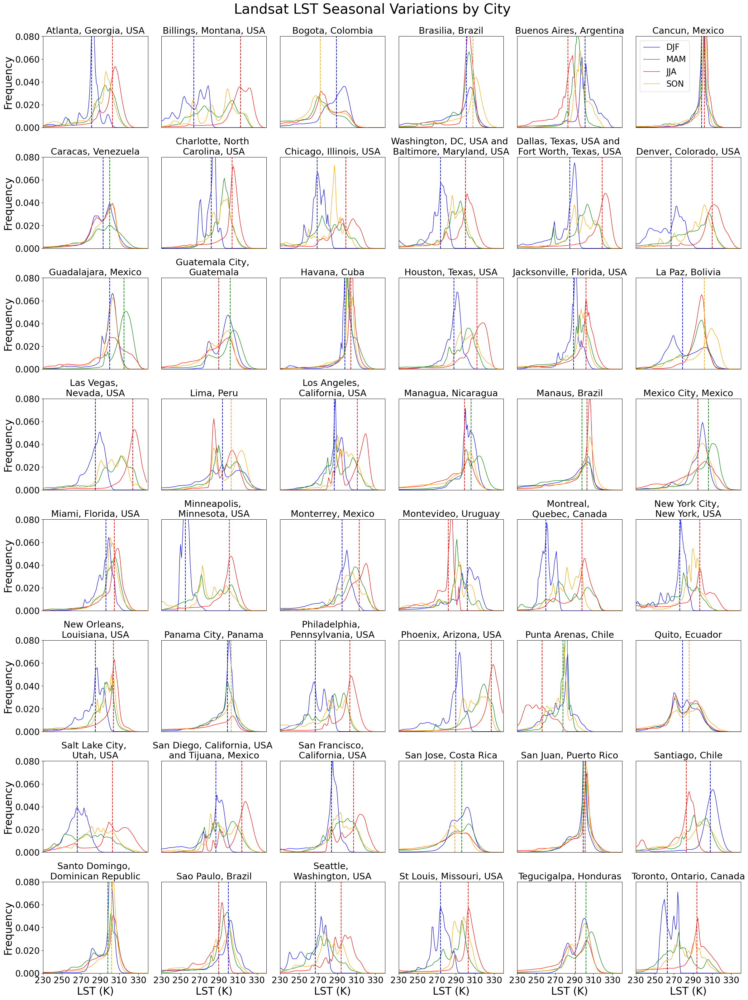

In [12]:
# Set up plot axes and general variables
fig, axs = plt.subplots(8, 6)
fig.set_size_inches(24, 32)
x = np.arange(230, 340)
colors = ['b', 'g', 'r', 'orange']

for i in range(8):
    print(i)
    for j in range(6):
        # Get the month of each Landsat file for the given city
        city = cities[i*6+j]
        city_list = city_Landsat_lists[city]
        month_list = np.array([dt.month for dt in date_dict[city]])

        # Fit a PDF to the Landsat LST data from December, January,
        # and February for the given city, and plot it
        DJF_indices = np.where(np.logical_or(month_list==12, month_list<3))
        data = get_LST_arrs(city_list[DJF_indices]).flatten()
        pdf = KDEUnivariate(data[~np.isnan(data)])
        pdf.fit()
        DJF = pdf.evaluate(x)
        axs[i, j].plot(x, DJF, color='b', linewidth=1, label='DJF')

        # Fit a PDF to the Landsat LST data from March, April,
        # and May for the given city, and plot it
        MAM_indices = np.where(np.logical_and(month_list>=3, month_list<6))
        data = get_LST_arrs(city_list[MAM_indices]).flatten()
        pdf = KDEUnivariate(data[~np.isnan(data)])
        pdf.fit()
        MAM = pdf.evaluate(x)
        axs[i, j].plot(x, MAM, color='g', linewidth=1, label='MAM')

        # Fit a PDF to the Landsat LST data from June, July,
        # and August for the given city, and plot it
        JJA_indices = np.where(np.logical_and(month_list>=6, month_list<9))
        data = get_LST_arrs(city_list[JJA_indices]).flatten()
        pdf = KDEUnivariate(data[~np.isnan(data)])
        pdf.fit()
        JJA = pdf.evaluate(x)
        axs[i, j].plot(x, JJA, color='r', linewidth=1, label='JJA')

        # Fit a PDF to the Landsat LST data from September, October,
        # and November for the given city, and plot it
        SON_indices = np.where(np.logical_and(month_list>=9, month_list<12))
        data = get_LST_arrs(city_list[SON_indices]).flatten()
        pdf = KDEUnivariate(data[~np.isnan(data)])
        pdf.fit()
        SON = pdf.evaluate(x)
        axs[i, j].plot(x, SON, color='orange', linewidth=1, label='SON')

        # Find the middle point of each distribution and plot a
        # vertical line at the minimum and maximum values,
        # following the color of the respective min and max seasons
        DJF_middle = x[np.where(np.cumsum(DJF) < 0.5)[0][-1]]
        MAM_middle = x[np.where(np.cumsum(MAM) < 0.5)[0][-1]]
        JJA_middle = x[np.where(np.cumsum(JJA) < 0.5)[0][-1]]
        SON_middle = x[np.where(np.cumsum(SON) < 0.5)[0][-1]]
        max_middle = np.max([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        max_index = np.argmax([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        min_middle = np.min([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        min_index = np.argmin([DJF_middle, MAM_middle, JJA_middle, SON_middle])

        # The JJA distribution for Panama City does not have a
        # cumulative sum of 0.5 in the given x range, so its max
        # would be set at the last x value. JJA and SON peak at the
        # same x, so the max value is set at SON's max
        if city == 'Panama_City':
            max_middle = SON_middle
            max_index = 3

        max_c = colors[max_index]
        min_c = colors[min_index]
        axs[i, j].axvline(x=max_middle, color=max_c, linestyle='--')
        axs[i, j].axvline(x=min_middle, color=min_c, linestyle='--')

        axs[i, j].set_title(city_str_dict[city], fontsize=21)

        # Format y-axis ticks to 3 decimal places
        formatter_y = mticker.StrMethodFormatter("{x:.3f}")
        axs[i, j].yaxis.set_major_formatter(formatter_y)
        axs[i, j].set_xlim(left=230, right=340)
        axs[i, j].set_xticks([])
        axs[i, j].set_ylim(bottom=0, top=0.08)
        axs[i, j].set_yticks([])

        # Set axis ticks and labels for the
        # left and bottom edges
        if j == 0:
            axs[i, j].set_ylabel('Frequency', fontsize=24)
            axs[i, j].set_yticks(np.arange(0, 0.081, 0.02))
            axs[i, j].tick_params(axis='y', labelsize=20)
        if i == 7:
            axs[i, j].set_xlabel('LST (K)', fontsize=24)
            axs[i, j].set_xticks(np.arange(230, 341, 20))
            axs[i, j].tick_params(axis='x', labelsize=20)

# Add a legend
handles, labels = axs[0, 0].get_legend_handles_labels()
axs[0, 5].legend(handles, labels, fontsize=19, loc='upper left')

# Add a title and save the figure
plt.suptitle('Landsat LST Seasonal Variations by City', y=1.001, fontsize=32)
plt.tight_layout()
fig.savefig('/glade/derecho/scratch/jstarfeldt/data_analysis/plots/LST_seasonal_variation.pdf', transparent=True, bbox_inches='tight')

In [14]:
def get_GOES_temps(city, season_code):
    """
    Returns an array of GOES BT band 14 values for a certain season out of all GOES files
    that overlap in time with a Landsat file of dimensions (day, band, y, x)

    Args:
    city (str): name of a city from the "cities" array
    season_code (str): One of ['DJF', 'MAM', 'JJA', 'SON'] for December/January/February,
                        March/April/May, June/July/August, or September/October/November

    Returns:
    GOES_data (np.array): Array of GOES temperature data
    """
    if season_code == 'DJF':
        months = [12, 1, 2]
    elif season_code == 'MAM':
        months = [3, 4, 5]
    elif season_code == 'JJA':
        months = [6, 7, 8]
    else:
        months = [9, 10, 11]

    GOES_temp_data = []
    for dt in GOES_date_dict[city]:
        if dt.month in months:
            dt_str = dt.strftime("%Y%m%d%H%M")
            data = xr.open_dataset(f'{dataset_root}/lresgrid/{str(dt.year)}/{stringify(dt.month)}/{city_ICAO_codes[city]}/lresgrid_{city_ICAO_codes[city]}_{dt_str}.nc')
            GOES_temp_data.append(data[list(data.data_vars)[:4]].to_dataarray()[1])
    GOES_data = np.stack(GOES_temp_data)
    return GOES_data

0
1
2
3
4
5
6
7


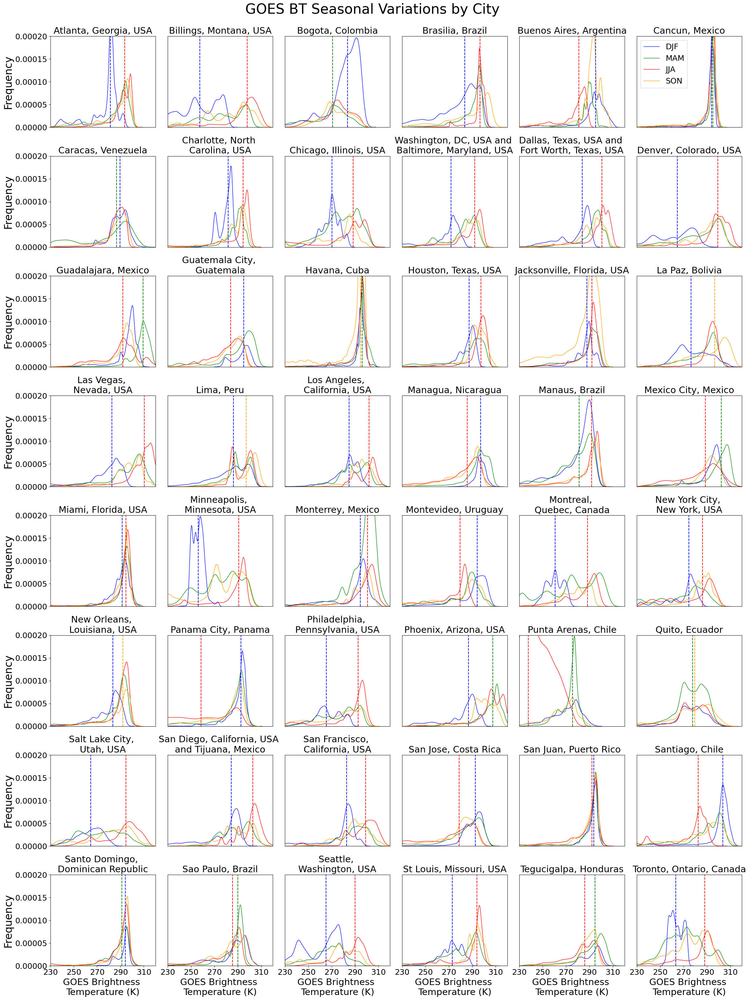

In [26]:
# Set up plot axes and general variables
fig, axs = plt.subplots(8, 6)
fig.set_size_inches(24, 32)
colors = ['b', 'g', 'r', 'orange']

for i in range(8):
    print(i)
    for j in range(6):
        city = cities[i*6+j]

        # Fit a PDF to the GOES BT data from December, January,
        # and February for the given city
        data = get_GOES_temps(city, 'DJF')
        DJF_pdf = KDEUnivariate(data.flatten())
        DJF_pdf.fit()

        # Fit a PDF to the GOES BT data from March, April,
        # and May for the given city
        data = get_GOES_temps(city, 'MAM')
        MAM_pdf = KDEUnivariate(data.flatten())
        MAM_pdf.fit()

        # Fit a PDF to the GOES BT data from June, July,
        # and August for the given city
        data = get_GOES_temps(city, 'JJA')
        JJA_pdf = KDEUnivariate(data.flatten())
        JJA_pdf.fit()

        # Fit a PDF to the GOES BT data from September, October,
        # and November for the given city
        data = get_GOES_temps(city, 'SON')
        SON_pdf = KDEUnivariate(data.flatten())
        SON_pdf.fit()

        # Create normalized PDFs
        DJF = DJF_pdf.density/np.sum(DJF_pdf.density)
        MAM = MAM_pdf.density/np.sum(MAM_pdf.density)
        JJA = JJA_pdf.density/np.sum(JJA_pdf.density)
        SON = SON_pdf.density/np.sum(SON_pdf.density)

        # Plot the normalized PDFs
        axs[i, j].plot(DJF_pdf.support, DJF, color='b', linewidth=1, label='DJF')
        axs[i, j].plot(MAM_pdf.support, MAM, color='g', linewidth=1, label='MAM')
        axs[i, j].plot(JJA_pdf.support, JJA, color='r', linewidth=1, label='JJA')
        axs[i, j].plot(SON_pdf.support, SON, color='orange', linewidth=1, label='SON')
        axs[i, j].set_title(city_str_dict[city], fontsize=21)

        # Find the middle point of each distribution and plot a
        # vertical line at the minimum and maximum values,
        # following the color of the respective min and max seasons
        DJF_middle = DJF_pdf.support[np.where(np.cumsum(DJF) < 0.5)[0][-1]]
        MAM_middle = MAM_pdf.support[np.where(np.cumsum(MAM) < 0.5)[0][-1]]
        JJA_middle = JJA_pdf.support[np.where(np.cumsum(JJA) < 0.5)[0][-1]]
        SON_middle = SON_pdf.support[np.where(np.cumsum(SON) < 0.5)[0][-1]]
        max_middle = np.max([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        max_index = np.argmax([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        min_middle = np.min([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        min_index = np.argmin([DJF_middle, MAM_middle, JJA_middle, SON_middle])

        max_c = colors[max_index]
        min_c = colors[min_index]
        axs[i, j].axvline(x=max_middle, color=max_c, linestyle='--')
        axs[i, j].axvline(x=min_middle, color=min_c, linestyle='--')

        # Format y-axis ticks to 3 decimal places
        formatter_y = mticker.StrMethodFormatter("{x:.5f}")
        axs[i, j].yaxis.set_major_formatter(formatter_y)
        axs[i, j].set_xlim(left=230, right=320)
        axs[i, j].set_ylim(bottom=0, top=0.0002)
        axs[i, j].set_yticks([])
        axs[i, j].set_xticks([])

        # Set axis ticks and labels for the left and bottom edges
        if j == 0:
            axs[i, j].set_ylabel('Frequency', fontsize=24)
            axs[i, j].set_yticks(np.arange(0, 0.00021, 0.00005))
            axs[i, j].tick_params(axis='y', labelsize=18)
        if i == 7:
            axs[i,j].set_xlabel('GOES Brightness \nTemperature (K)', fontsize=21)
            axs[i, j].set_xticks(np.arange(230, 321, 20))
            axs[i, j].tick_params(axis='x', labelsize=18)

handles, labels = axs[0, 0].get_legend_handles_labels()
axs[0, 5].legend(handles, labels, fontsize=18, loc='upper left', ncols=1)

plt.suptitle('GOES BT Seasonal Variations by City', y=1.001, fontsize=32)
plt.tight_layout()
fig.savefig('/glade/derecho/scratch/jstarfeldt/data_analysis/plots/GOES_BT_seasonal_variation.pdf', transparent=True, bbox_inches='tight')

0
1
2
3
4
5
6
7


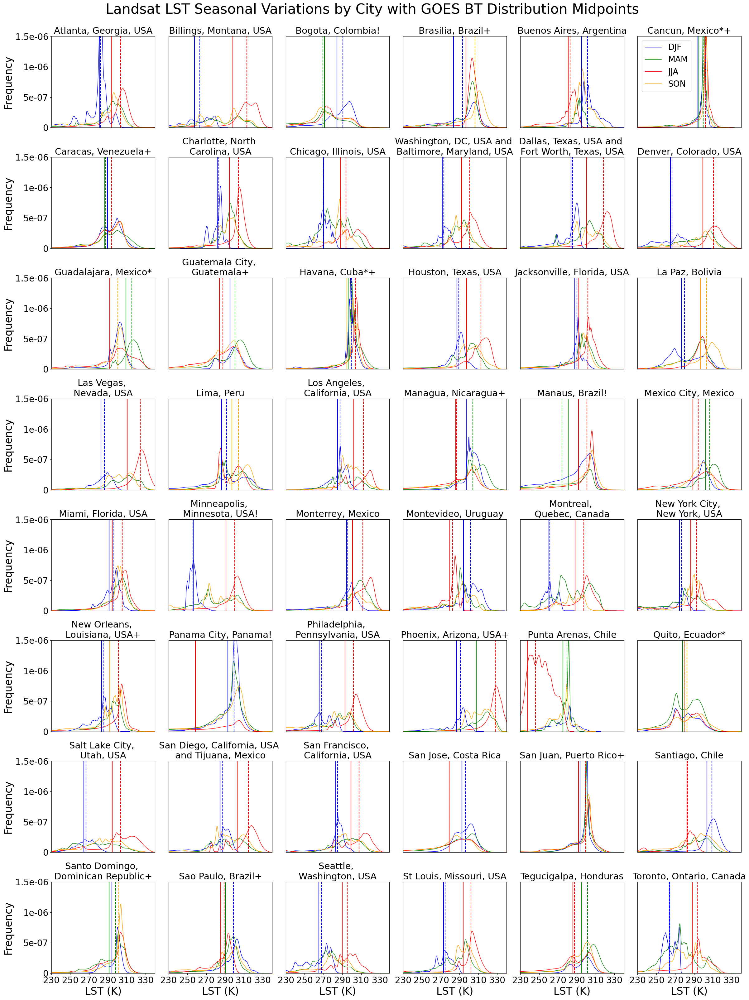

In [15]:
# Set up plot axes and general variables
fig, axs = plt.subplots(8, 6)
fig.set_size_inches(24, 32)
x = np.arange(230, 340)
colors = ['b', 'g', 'r', 'orange']

for i in range(8):
    print(i)
    for j in range(6):
        # Get the month of each Landsat file for the given city
        city = cities[i*6+j]
        city_list = np.array(city_Landsat_lists[city])
        month_list = np.array([dt.month for dt in date_dict[city]])

        # Fit a PDF to the Landsat LST data from December, January,
        # and February for the given city, and plot it
        DJF_indices = np.where(np.logical_or(month_list==12, month_list<3))[0]
        data = get_LST_arrs(city_list[DJF_indices]).flatten()
        pdf = KDEUnivariate(data[~np.isnan(data)])
        pdf.fit()
        DJF = pdf.density/np.sum(pdf.density)
        DJF_middle = pdf.support[np.where(np.cumsum(DJF) < 0.5)[0][-1]]
        axs[i, j].plot(pdf.support, DJF, color='b', linewidth=1, label='DJF')[0]

        # Fit a PDF to the Landsat LST data from March, April,
        # and May for the given city, and plot it
        MAM_indices = np.where(np.logical_and(month_list>=3, month_list<6))[0]
        data = get_LST_arrs(city_list[MAM_indices]).flatten()
        pdf = KDEUnivariate(data[~np.isnan(data)])
        pdf.fit()
        MAM = pdf.density/np.sum(pdf.density)
        MAM_middle = pdf.support[np.where(np.cumsum(MAM) < 0.5)[0][-1]]
        axs[i, j].plot(pdf.support, MAM, color='g', linewidth=1, label='MAM')[0]

        # Fit a PDF to the Landsat LST data from June, July,
        # and August for the given city, and plot it
        JJA_indices = np.where(np.logical_and(month_list>=6, month_list<9))
        data = get_LST_arrs(city_list[JJA_indices]).flatten()
        pdf = KDEUnivariate(data[~np.isnan(data)])
        pdf.fit()
        JJA = pdf.density/np.sum(pdf.density)
        JJA_middle = pdf.support[np.where(np.cumsum(JJA) < 0.5)[0][-1]]
        axs[i, j].plot(pdf.support, JJA, color='r', linewidth=1, label='JJA')

        # Fit a PDF to the Landsat LST data from September, October,
        # and November for the given city, and plot it
        SON_indices = np.where(np.logical_and(month_list>=9, month_list<12))
        data = get_LST_arrs(city_list[SON_indices]).flatten()
        pdf = KDEUnivariate(data[~np.isnan(data)])
        pdf.fit()
        SON = pdf.density/np.sum(pdf.density)
        SON_middle = pdf.support[np.where(np.cumsum(SON) < 0.5)[0][-1]]
        axs[i, j].plot(pdf.support, SON, color='orange', linewidth=1, label='SON')

        # Plot a vertical line at the minimum and maximum middle point
        # values, following the color of the respective min and max seasons
        LS_max_middle = np.max([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        LS_max_index = np.argmax([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        LS_min_middle = np.min([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        LS_min_index = np.argmin([DJF_middle, MAM_middle, JJA_middle, SON_middle])

        max_c = colors[LS_max_index]
        min_c = colors[LS_min_index]
        axs[i, j].axvline(x=LS_max_middle, color=max_c, linestyle='--')
        axs[i, j].axvline(x=LS_min_middle, color=min_c, linestyle='--')

        #####################################################################
        # GOES BT code
        # Fit a PDF to the GOES BT data from December, January,
        # and February for the given city
        data = get_GOES_temps(city, 'DJF')
        DJF_pdf = KDEUnivariate(data.flatten())
        DJF_pdf.fit()

        # Fit a PDF to the GOES BT data from March, April,
        # and May for the given city
        data = get_GOES_temps(city, 'MAM')
        MAM_pdf = KDEUnivariate(data.flatten())
        MAM_pdf.fit()

        # Fit a PDF to the GOES BT data from June, July,
        # and August for the given city
        data = get_GOES_temps(city, 'JJA')
        JJA_pdf = KDEUnivariate(data.flatten())
        JJA_pdf.fit()

        # Fit a PDF to the GOES BT data from September, October,
        # and November for the given city
        data = get_GOES_temps(city, 'SON')
        SON_pdf = KDEUnivariate(data.flatten())
        SON_pdf.fit()

        # Calculate the PDFs
        DJF = DJF_pdf.density/np.sum(DJF_pdf.density)
        MAM = MAM_pdf.density/np.sum(MAM_pdf.density)
        JJA = JJA_pdf.density/np.sum(JJA_pdf.density)
        SON = SON_pdf.density/np.sum(SON_pdf.density)

        # Find the middle point of each distribution and plot a
        # vertical line at the minimum and maximum values,
        # following the color of the respective min and max seasons
        DJF_middle = DJF_pdf.support[np.where(np.cumsum(DJF) < 0.5)[0][-1]]
        MAM_middle = MAM_pdf.support[np.where(np.cumsum(MAM) < 0.5)[0][-1]]
        JJA_middle = JJA_pdf.support[np.where(np.cumsum(JJA) < 0.5)[0][-1]]
        SON_middle = SON_pdf.support[np.where(np.cumsum(SON) < 0.5)[0][-1]]
        GOES_max_middle = np.max([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        GOES_max_index = np.argmax([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        GOES_min_middle = np.min([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        GOES_min_index = np.argmin([DJF_middle, MAM_middle, JJA_middle, SON_middle])

        max_c = colors[GOES_max_index]
        min_c = colors[GOES_min_index]
        axs[i, j].axvline(x=GOES_max_middle, color=max_c, linestyle='solid')
        axs[i, j].axvline(x=GOES_min_middle, color=min_c, linestyle='solid')

        #############################################################
        # Plot title
        title = city_str_dict[city]
        if LS_min_index != GOES_min_index:
            title = title + '*'
        if LS_max_index != GOES_max_index:
            title = title + '+'
        if GOES_min_middle > LS_min_middle:
            title = title + '!'
        if GOES_max_middle > GOES_max_middle:
            title = title + '#'
        axs[i, j].set_title(title, fontsize=21)

        # Format y-axis ticks to 3 decimal places
        formatter_y = mticker.StrMethodFormatter("{x:.7f}")
        axs[i, j].yaxis.set_major_formatter(formatter_y)
        axs[i, j].set_xlim(left=230, right=340)
        axs[i, j].set_xticks([])
        axs[i, j].set_ylim(bottom=0, top=0.0000015)
        axs[i, j].set_yticks([])

        # Set axis ticks and labels for the
        # left and bottom edges
        if j == 0:
            axs[i, j].set_ylabel('Frequency', fontsize=24)
            axs[i, j].set_yticks(np.arange(0, 0.0000016, 0.0000005), labels=[0, 5.0e-7, 1.0e-6, 1.5e-6])
            axs[i, j].tick_params(axis='y', labelsize=20)
        if i == 7:
            axs[i, j].set_xlabel('LST (K)', fontsize=24)
            axs[i, j].set_xticks(np.arange(230, 341, 20))
            axs[i, j].tick_params(axis='x', labelsize=20)

# Add a legend
handles, labels = axs[0, 0].get_legend_handles_labels()
axs[0, 5].legend(handles, labels, fontsize=19, loc='upper left')

# Add a title and save the figure
plt.suptitle('Landsat LST Seasonal Variations by City with GOES BT Distribution Midpoints', y=1.001, fontsize=32)
plt.tight_layout()
fig.savefig('/glade/derecho/scratch/jstarfeldt/data_analysis/plots/LST_BT_seasonal_variation.pdf', transparent=True, bbox_inches='tight')

## Cloud fraction

In [24]:
def index(val):
    """
    Extracts the "cloud" bit value from a Landsat cloud mask bit string.

    Args:
    val (char): Pixel value from Landsat cloud mask

    Returns:
    True if the cloud pixel is 1, otherwise False
    """
    try:
        return str(int(val))[-4] == '1'
    except:
        return False

# Vectorize index function
cloud_func = np.vectorize(index)

In [11]:
# Dictionary to store pixel cloud fractions
# for each city
cloud_dict = {string: [] for string in cities}
cloud_dict

{'Atlanta': [],
 'Billings': [],
 'Bogota': [],
 'Brasilia': [],
 'Buenos_Aires': [],
 'Cancun': [],
 'Caracas': [],
 'Charlotte': [],
 'Chicago': [],
 'DMV': [],
 'Dallas': [],
 'Denver': [],
 'Guadalajara': [],
 'Guatemala_City': [],
 'Havana': [],
 'Houston': [],
 'Jacksonville': [],
 'La_Paz': [],
 'Las_Vegas': [],
 'Lima': [],
 'Los_Angeles': [],
 'Managua': [],
 'Manaus': [],
 'Mexico_City': [],
 'Miami': [],
 'Minneapolis': [],
 'Monterrey': [],
 'Montevideo': [],
 'Montreal': [],
 'NYC': [],
 'New_Orleans': [],
 'Panama_City': [],
 'Philadelphia': [],
 'Phoenix': [],
 'Punta_Arenas': [],
 'Quito': [],
 'Salt_Lake_City': [],
 'San_Diego': [],
 'San_Francisco': [],
 'San_Jose': [],
 'San_Juan': [],
 'Santiago': [],
 'Santo_Domingo': [],
 'Sao_Paulo': [],
 'Seattle': [],
 'St_Louis': [],
 'Tegucigalpa': [],
 'Toronto': []}

In [20]:
# For each city in the dataset, loop through the Landsat files
# and save the percentage of non-NaN pixels marked as a cloud by the
# Landsat cloud mask to the cloud_dict dictionary
for city in cities:
    print(city)
    city_list = city_Landsat_lists[city]

    for file in city_list:
        data = xr.open_dataset(file)['Landsat_cloud_mask'].values
        pixels = np.sum(np.where(np.nan_to_num(data) == 0, 0, 1))
        cloud = cloud_func(data)
        cloud_frac = np.sum(cloud)/pixels
        cloud_dict[city].append(cloud_frac)

# Save the cloud_dict as a pickle
with open('/glade/derecho/scratch/jstarfeldt/data_analysis/all_cloud_dicts.pkl', 'wb') as file:
    pickle.dump(cloud_dict, file)

Santo_Domingo
Sao_Paulo
Seattle
St_Louis
Tegucigalpa
Toronto


In [36]:
# Re-open the cloud_dict pickle
with open('/glade/derecho/scratch/jstarfeldt/data_analysis/all_cloud_dicts.pkl', 'rb') as file:
    cloud_dict = pickle.load(file)

In [37]:
# Sort the cloud_dict dictionary by the median of its array values
sorted_data = dict(sorted(cloud_dict.items(), key=lambda item: np.median(item[1]), reverse=True))
sorted_data.keys()

dict_keys(['Bogota', 'Quito', 'Seattle', 'San_Jose', 'Panama_City', 'Caracas', 'Manaus', 'Punta_Arenas', 'Guatemala_City', 'Sao_Paulo', 'Tegucigalpa', 'Santo_Domingo', 'Philadelphia', 'Toronto', 'New_Orleans', 'Chicago', 'Lima', 'San_Juan', 'Miami', 'Managua', 'Montevideo', 'Montreal', 'Houston', 'Jacksonville', 'DMV', 'NYC', 'Atlanta', 'Cancun', 'La_Paz', 'Minneapolis', 'Havana', 'San_Diego', 'Mexico_City', 'Salt_Lake_City', 'Charlotte', 'Los_Angeles', 'St_Louis', 'Billings', 'Denver', 'Monterrey', 'San_Francisco', 'Buenos_Aires', 'Brasilia', 'Dallas', 'Santiago', 'Guadalajara', 'Las_Vegas', 'Phoenix'])

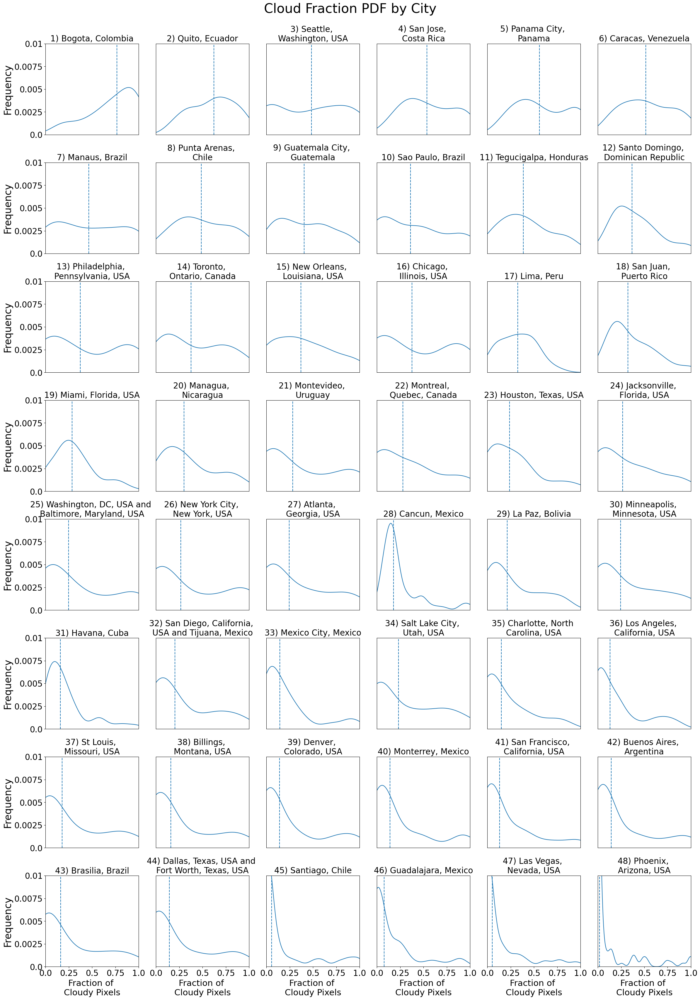

In [38]:
# Set up plot axes and general variables
fig, axs = plt.subplots(8, 6)
fig.set_size_inches(24, 34)
plt.setp(plt.gcf().get_axes(), xticks=[], yticks=[])
colors = cm.jet(np.linspace(0, 1, 48))
sorted_cities = list(sorted_data.keys())
x = np.arange(0, 1.01, 0.02)

i = 0
for ax in axs:
    for box in ax:
        city = sorted_cities[i]

        # Create PDF of city cloudy pixel percentages
        pdf = KDEUnivariate(cloud_dict[city])
        pdf.fit()

        # Plot the PDF of cloudy pixel percentages and a
        # vertical line at the median
        box.plot(pdf.support, pdf.density/np.sum(pdf.density))

        middle = pdf.support[np.where(pdf.cdf >= 0.5)[0][0]]
        box.axvline(x=middle, linestyle='--')

        # Set axis title
        box.set_title(f'{i+1}) {ordered_city_str_dict[city]}', fontsize=20)
        box.set_ylim(0, 0.01)
        box.set_xlim(0, 1)

        # Set axis ticks and labels for the left and bottom edges
        if i % 6 == 0: # First box in each row
            box.set_ylabel('Frequency', fontsize=24)
            box.set_yticks(np.arange(0, 0.011, 0.0025), labels=np.arange(0, 0.011, 0.0025), fontsize=20)
        else:
            box.set_yticks([])
        if i >= 42: # Last row
            box.set_xlabel('Fraction of \nCloudy Pixels', fontsize=21)
            box.set_xticks(np.arange(0, 1.1, 0.25), labels=np.arange(0, 1.1, 0.25), fontsize=20)
        else:
            box.set_xticks([])
        i += 1

# Set a title and save the figure
plt.suptitle('Cloud Fraction PDF by City', y=1.001, fontsize=32)
plt.tight_layout()
fig.savefig('/glade/derecho/scratch/jstarfeldt/data_analysis/plots/cloud_fraction_pdfs.pdf', transparent=True, bbox_inches='tight')

## Variable Correlation

In [25]:
def calculate_corr_matrix(file):
    """
    Calculates the correlation matrix for variables in a Landsat/Sentinel-1 file,
    including Landsat surface reflectances, Landsat LST, and Sentinel-1 SAR
    VV and VH. Pixels with NaN values for any variable are ignored.

    Args:
    file (str): Full string of the Landsat/Sentinel-1 file location

    Returns:
    (np.array): Correlation matrix between Landsat/Sentinel-1 variables
    """
    ds = xr.open_dataset(file)
    arr = ds[['Landsat_blue_sfc_reflectance', 'Landsat_green_sfc_reflectance', 'Landsat_red_sfc_reflectance', 'Landsat_NIR_sfc_reflectance',
          'Landsat_SWIR1_sfc_reflectance', 'Landsat_SWIR2_sfc_reflectance', 'Landsat_LST', 'Sentinel1_VV', 'Sentinel1_VH']]\
        .to_dataarray().values.reshape((9,-1))

    nan_columns = np.isnan(arr).any(axis=0) # Identify columns with NaNs
    filtered_array = arr[:, ~nan_columns] # Filter out columns with NaN

    return np.corrcoef(filtered_array)

In [26]:
# Calculates the correlation matrix for every Landsat/Sentinel-1 file in the dataset,
# then takes the mean of each correlation for each city, saving them in a pickle
for city in cities:
    corr_matrices = []
    city_list = city_Landsat_lists[city]

    for file in city_list:
        corr_matrices.append(calculate_corr_matrix(file))

    corr_matrix = np.nanmean(corr_matrices, axis=0)
    with open(f'/glade/derecho/scratch/jstarfeldt/data_analysis/corr_matrices/{city}_corr_matrix.pkl', 'wb') as file:
        pickle.dump(corr_matrix, file)

0
1
2
3
4
5
6
7


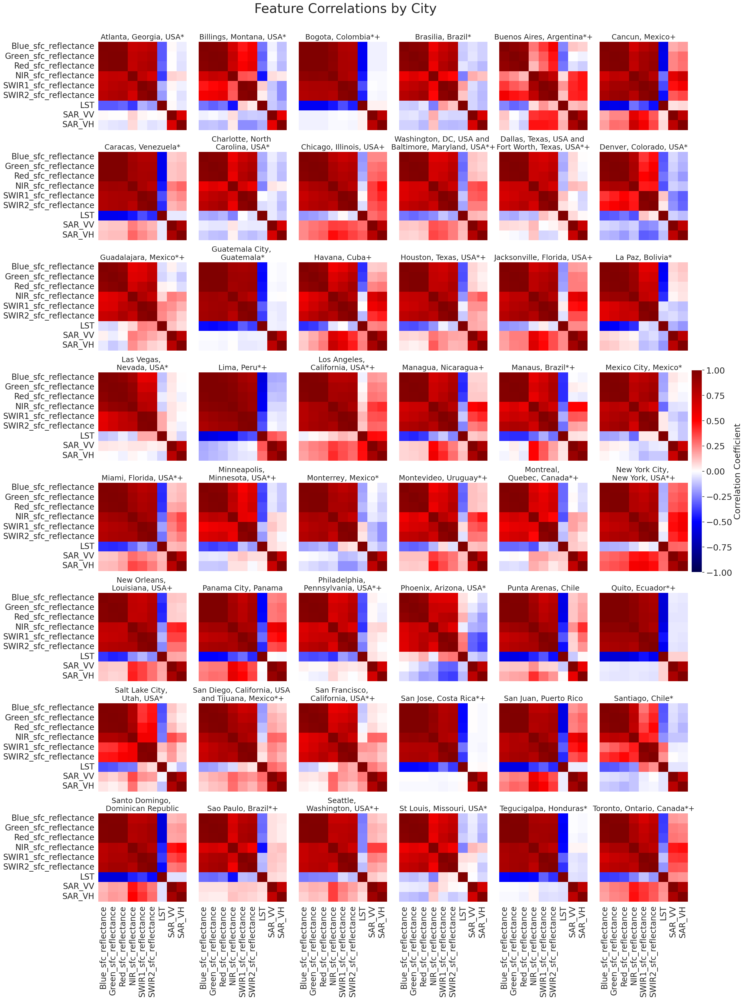

In [12]:
# Set up plot axes and general variables
fig, axs = plt.subplots(8, 6)
fig.set_size_inches(24, 34)
sns.set(font_scale=1.8)

# Defines the variables in the correlation matrices
vars = ['Blue_sfc_reflectance', 'Green_sfc_reflectance', 'Red_sfc_reflectance', 'NIR_sfc_reflectance',
        'SWIR1_sfc_reflectance', 'SWIR2_sfc_reflectance', 'LST', 'SAR_VV', 'SAR_VH']

# Plot the mean correlation matrix for each city as a heatmap
for i in range(8):
    print(i)
    for j in range(6):
        city = cities[i*6+j]
        with open(f'/glade/derecho/scratch/jstarfeldt/data_analysis/corr_matrices/{city}_corr_matrix.pkl', 'rb') as file:
            corr_matrix = pickle.load(file)
        if j == 0 and i == 7: # Label both axes for bottom left plot
            sns.heatmap(corr_matrix, xticklabels=vars, yticklabels=vars, annot=False,
                        cmap='seismic', vmin=-1, vmax=1, cbar=False, square=True, ax=axs[i,j])
        elif i == 7: # Label x axis for last plot of each column
            sns.heatmap(corr_matrix, xticklabels=vars, yticklabels=[], annot=False,
                        cmap='seismic', vmin=-1, vmax=1, cbar=False, square=True, ax=axs[i,j])
        elif j == 0: # Label y axis for first plot of each row
            sns.heatmap(corr_matrix, yticklabels=vars, xticklabels=[], annot=False,
                        cmap='seismic', vmin=-1, vmax=1, cbar=False, square=True, ax=axs[i,j])
        else:
            sns.heatmap(corr_matrix, xticklabels=[], yticklabels=[], annot=False,
                        cmap='seismic', vmin=-1, vmax=1, cbar=False, square=True, ax=axs[i,j])

        # Set special subplot title
        LST_reflectance_corrs = corr_matrix[6, :6]
        LST_SAR_corrs = corr_matrix[6,  7:]
        title = city_str_dict[city]
        # If SWIR1 and SWIR2 are the reflectances with the largest two
        # correlations with Landsat LST, add an asterisk to the title
        if set(np.argpartition(LST_reflectance_corrs, -2)[-2:]) == set([4, 5]):
            title = title+'*'
        # If SAR VV and SAR VH both have positive correlations
        # with Landsat LST, add a plus sign to the title
        if np.all(LST_SAR_corrs > 0):
            title = title+'+'
        axs[i,j].set_title(title, fontsize=18)

# Add a plot title
plt.suptitle('Feature Correlations by City', y=1.001, fontsize=32)
plt.tight_layout()

# Add a colorbar
cmap = cm.seismic
norm = Normalize(vmin=-1, vmax=1)
cb = cm.ScalarMappable(norm=norm, cmap=cmap)
cbar_ax = fig.add_axes([0.99, 0.432, 0.015, 0.202])
cbar = fig.colorbar(cb, cax=cbar_ax)
cbar.set_label(label='Correlation Coefficient', size=21)
cbar.ax.tick_params(labelsize=21)

# Save the figure
#plt.show()
fig.savefig('/glade/derecho/scratch/jstarfeldt/data_analysis/plots/city_feature_correlations.pdf', transparent=True, bbox_inches='tight')

## Seasonal Spatial Variability

In [17]:
# Create a dictionary where each city maps to a list of the spatial
# standard deviation values of each of its Landsat LST images
var_dict = {}

for city in cities:
    LST_vars = []
    city_list = city_Landsat_lists[city]

    for file in city_list:
        arr = xr.open_dataset(file)['Landsat_LST'].values
        LST_vars.append(np.nanstd(arr))

    var_dict[city] = LST_vars

# Save the dictionary to a pickle
with open(f'/glade/derecho/scratch/jstarfeldt/data_analysis/LST_spatial_stds.pkl', 'wb') as file:
    pickle.dump(var_dict, file)

/glade/u/home/jstarfeldt/.conda/envs/heat/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [18]:
# Load the Landsat LST spatial standard deviation pickle
with open(f'/glade/derecho/scratch/jstarfeldt/data_analysis/LST_spatial_stds.pkl', 'rb') as file:
    var_dict = pickle.load(file)

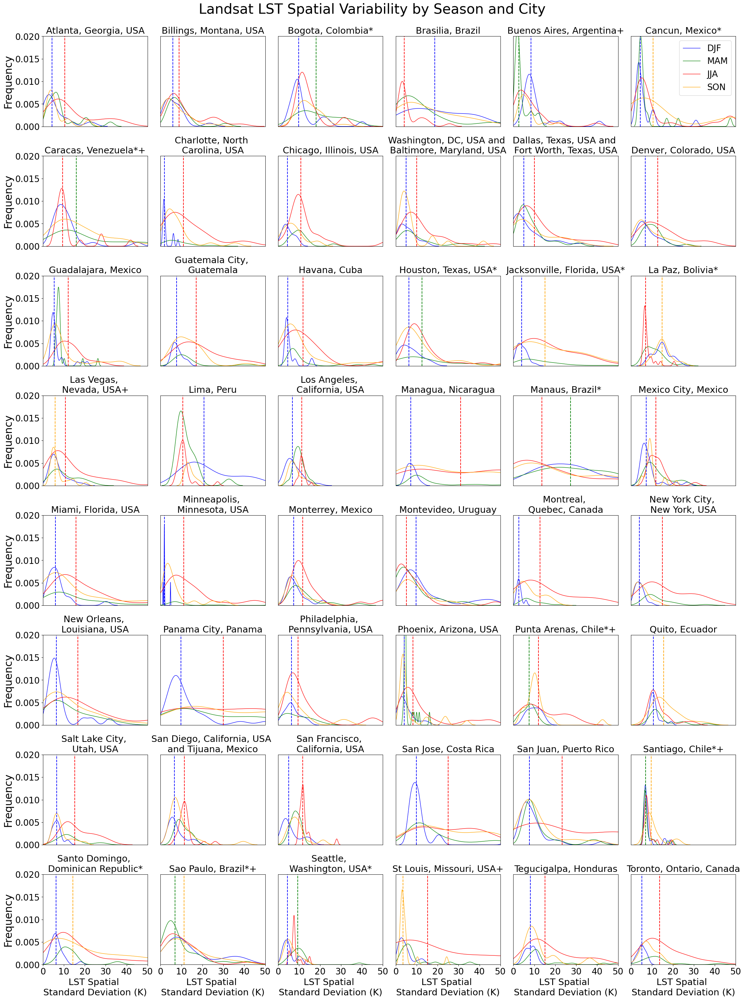

In [19]:
# Set up plot axes and general variables
fig, axs = plt.subplots(8, 6)
fig.set_size_inches(24, 32)
x = np.linspace(0, 41, 200)
colors = ['b', 'g', 'r', 'orange']

for i in range(8):
    for j in range(6):
        # Gets the month and Landsat LST spatial standard deviation
        # data for each Landsat/Sentinel-1 file for a city
        city = cities[i*6+j]
        month_list = np.array([dt.month for dt in date_dict[city]])
        var_list = np.array(var_dict[city])

        # Index the LST spatial standard deviation list by month
        # to pick out a specific season. Fit a PDF to each season
        DJF_vars = var_list[np.where(np.logical_or(month_list==12, month_list<3))]
        DJF_vars = DJF_vars[~np.isnan(DJF_vars)]  # Only season with a fully-NaN image
        MAM_vars = var_list[np.where(np.logical_and(month_list>=3, month_list<6))]
        JJA_vars = var_list[np.where(np.logical_and(month_list>=6, month_list<9))]
        SON_vars = var_list[np.where(np.logical_and(month_list>=9, month_list<12))]
        DJF_pdf = KDEUnivariate(DJF_vars)
        DJF_pdf.fit()
        MAM_pdf = KDEUnivariate(MAM_vars)
        MAM_pdf.fit()
        JJA_pdf = KDEUnivariate(JJA_vars)
        JJA_pdf.fit()
        SON_pdf = KDEUnivariate(SON_vars)
        SON_pdf.fit()

        # Plot each seasonal PDF
        DJF = DJF_pdf.density/np.sum(DJF_pdf.density)
        MAM = MAM_pdf.density/np.sum(DJF_pdf.density)
        JJA = JJA_pdf.density/np.sum(JJA_pdf.density)
        SON = SON_pdf.density/np.sum(SON_pdf.density)

        axs[i, j].plot(DJF_pdf.support, DJF, color='b', linewidth=1, label='DJF')
        axs[i, j].plot(MAM_pdf.support, MAM, color='g', linewidth=1, label='MAM')
        axs[i, j].plot(JJA_pdf.support, JJA, color='r', linewidth=1, label='JJA')
        axs[i, j].plot(SON_pdf.support, SON, color='orange', linewidth=1, label='SON')

        # Calculate the midpoint of each seasonal PDF, get the
        # index of the minimum and maximum midpoints
        DJF_middle = DJF_pdf.support[np.where(DJF_pdf.cdf >= 0.5)[0][0]]
        MAM_middle = MAM_pdf.support[np.where(MAM_pdf.cdf >= 0.5)[0][0]]
        JJA_middle = JJA_pdf.support[np.where(JJA_pdf.cdf >= 0.5)[0][0]]
        SON_middle = SON_pdf.support[np.where(SON_pdf.cdf >= 0.5)[0][0]]
        max_middle = np.max([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        max_index = np.argmax([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        min_middle = np.min([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        min_index = np.argmin([DJF_middle, MAM_middle, JJA_middle, SON_middle])

        # Plot the minimum and maximum midpoints as dashed
        # vertical lines, of the corresponding season color
        max_c = colors[max_index]
        min_c = colors[min_index]
        axs[i, j].axvline(x=max_middle, color=max_c, linestyle='--')
        axs[i, j].axvline(x=min_middle, color=min_c, linestyle='--')

        # Format y-axis ticks to 3 decimal places
        formatter_y = mticker.StrMethodFormatter("{x:.3f}")
        axs[i, j].yaxis.set_major_formatter(formatter_y)
        axs[i, j].set_xlim(left=0, right=50)
        axs[i, j].set_xticks([])
        axs[i, j].set_ylim(bottom=0, top=0.02)
        axs[i, j].set_yticks([])

        # Set plot title
        title = city_str_dict[city]
        # Quito is on the equator, so we make no seasonal comparisons
        if city != 'Quito':
            # When summer is not the season with the largest variability
            if proj_zone[city][1] and max_index != 2:
                title = title + '*'
            elif not proj_zone[city][1] and max_index != 0:
                title = title + '*'
            # When winter is not the season with the smallest variability
            if proj_zone[city][1] and min_index != 0:
                title = title + '+'
            elif not proj_zone[city][1] and min_index != 2:
                title = title + '+'
        axs[i, j].set_title(title, fontsize=21)

        # Set axis ticks and labels for the left and bottom edges
        if j == 0:
            axs[i, j].set_ylabel('Frequency', fontsize=24)
            axs[i, j].set_yticks(np.arange(0, 0.021, 0.005))
            axs[i, j].tick_params(axis='y', labelsize=20)
        if i == 7:
            axs[i, j].set_xlabel('LST Spatial \nStandard Deviation (K)', fontsize=21)
            axs[i, j].set_xticks(np.arange(0, 51, 10))
            axs[i, j].tick_params(axis='x', labelsize=20)

# Add a legend
handles, labels = axs[0, 0].get_legend_handles_labels()
axs[0, 5].legend(handles, labels, fontsize=20, loc='upper right')

# Set a title and save the figure
plt.suptitle('Landsat LST Spatial Variability by Season and City', y=1.001, fontsize=32)
plt.tight_layout()
fig.savefig('/glade/derecho/scratch/jstarfeldt/data_analysis/plots/LST_spatial_variability_seasonal_variation.pdf', transparent=True, bbox_inches='tight')

In [17]:
def get_GOES_temp_variability(city, season_code):
    """
    Calculates the spatial standard deviation of GOES BT band 14
    in each GOES/MW LST file for a given city, following a specific
    season. 'DJF' corresponds to December, January, and February,
    'MAM' corresponds to March, April, and May, 'JJA' corresponds to
    June, July, and August, and 'SON' corresponds to September,
    October, and November.

    Args:
    city (str): city from the 'cities' list
    season_code (str): 'DJF', 'MAM', 'JJA', or 'SON'

    Returns:
    GOES_data (np.array): Array of spatial standard deviation of
                          GOES BTs. Will be of shape (n, 4), where n
                          is the number of GOES files in the given season
    """
    if season_code == 'DJF':
        months = [12, 1, 2]
    elif season_code == 'MAM':
        months = [3, 4, 5]
    elif season_code == 'JJA':
        months = [6, 7, 8]
    else:
        months = [9, 10, 11]

    GOES_var_data = []
    for dt in GOES_date_dict[city]:
        if dt.month in months:
            dt_str = dt.strftime("%Y%m%d%H%M")
            data = xr.open_dataset(f'{dataset_root}/lresgrid/{str(dt.year)}/{stringify(dt.month)}/{city_ICAO_codes[city]}/lresgrid_{city_ICAO_codes[city]}_{dt_str}.nc')
            GOES_var_data.append(np.nanstd(data[list(data.data_vars)[:4]].to_dataarray()[1]))
    GOES_var_data = np.array(GOES_var_data)
    return GOES_var_data

0
1
2
3
4
5
6
7


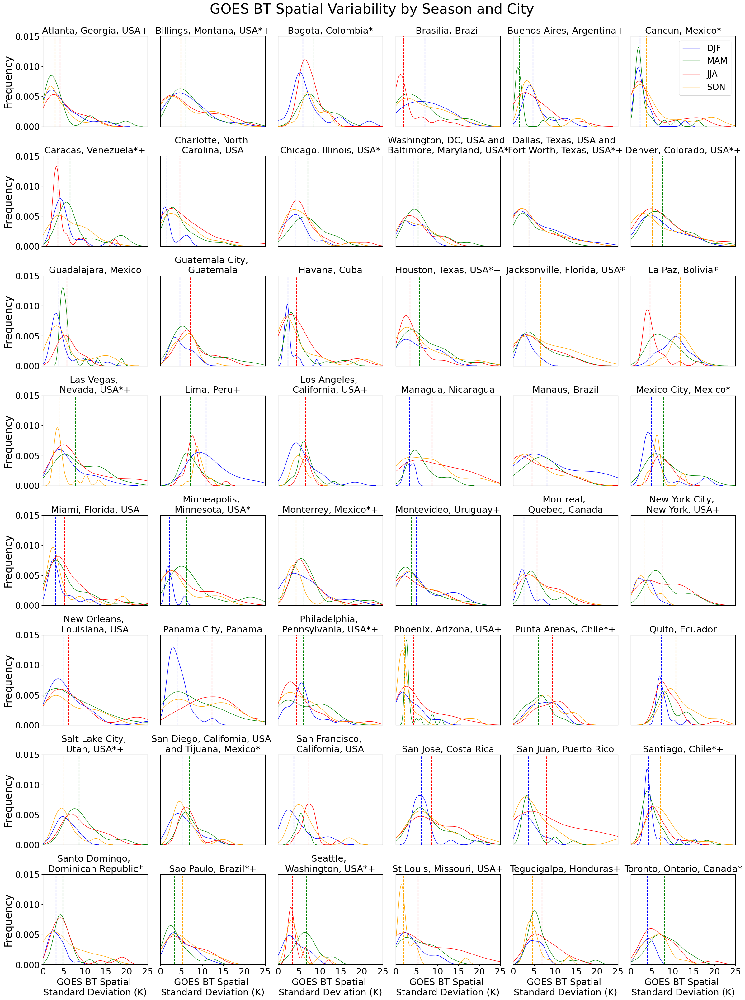

In [21]:
# Set up plot axes and general variables
fig, axs = plt.subplots(8, 6)
fig.set_size_inches(24, 32)
plt.subplots_adjust(hspace=0.2)
x = np.linspace(0, 16, 50)
colors = ['b', 'g', 'r', 'orange']

for i in range(8):
    print(i)
    for j in range(6):
        city = cities[i*6+j]

        # Get GOES BT spatial standard deviations for
        # each season. Fit a PDF to each season
        data = get_GOES_temp_variability(city, 'DJF')
        DJF_pdf = KDEUnivariate(data)
        DJF_pdf.fit()

        data = get_GOES_temp_variability(city, 'MAM')
        MAM_pdf = KDEUnivariate(data)
        MAM_pdf.fit()

        data = get_GOES_temp_variability(city, 'JJA')
        JJA_pdf = KDEUnivariate(data)
        JJA_pdf.fit()

        data = get_GOES_temp_variability(city, 'SON')
        SON_pdf = KDEUnivariate(data)
        SON_pdf.fit()

        # Plot the PDF for each season
        DJF = DJF_pdf.density/np.sum(DJF_pdf.density)
        MAM = MAM_pdf.density/np.sum(MAM_pdf.density)
        JJA = JJA_pdf.density/np.sum(JJA_pdf.density)
        SON = SON_pdf.density/np.sum(SON_pdf.density)
        axs[i, j].plot(DJF_pdf.support, DJF, color='b', linewidth=1, label='DJF')
        axs[i, j].plot(MAM_pdf.support, MAM, color='g', linewidth=1, label='MAM')
        axs[i, j].plot(JJA_pdf.support, JJA, color='r', linewidth=1, label='JJA')
        axs[i, j].plot(SON_pdf.support, SON, color='orange', linewidth=1, label='SON')
        axs[i, j].set_title(city_str_dict[city], fontsize=21)

        # Find the midpoint of the PDF for each season, get
        # the index of the minimum and maximium midpoints
        DJF_middle = DJF_pdf.support[np.where(DJF_pdf.cdf >= 0.5)[0][0]]
        MAM_middle = MAM_pdf.support[np.where(MAM_pdf.cdf >= 0.5)[0][0]]
        JJA_middle = JJA_pdf.support[np.where(JJA_pdf.cdf >= 0.5)[0][0]]
        SON_middle = SON_pdf.support[np.where(SON_pdf.cdf >= 0.5)[0][0]]
        max_middle = np.max([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        max_index = np.argmax([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        min_middle = np.min([DJF_middle, MAM_middle, JJA_middle, SON_middle])
        min_index = np.argmin([DJF_middle, MAM_middle, JJA_middle, SON_middle])

        # Plot the minimum and maximum midpoints as dashed
        # vertical lines, of the corresponding season color
        max_c = colors[max_index]
        min_c = colors[min_index]
        axs[i, j].axvline(x=max_middle, color=max_c, linestyle='--')
        axs[i, j].axvline(x=min_middle, color=min_c, linestyle='--')

        # Format y-axis ticks to 3 decimal places
        formatter_y = mticker.StrMethodFormatter("{x:.3f}")
        axs[i, j].yaxis.set_major_formatter(formatter_y)
        axs[i, j].set_xlim(left=0, right=25)
        axs[i, j].set_xticks([])
        axs[i, j].set_ylim(bottom=0, top=0.015)
        axs[i, j].set_yticks([])

        # Set plot title
        title = city_str_dict[city]
        # Quito is on the equator, so we make no seasonal comparisons
        if city != 'Quito':
            # When summer is not the season with the largest variability
            if proj_zone[city][1] and max_index != 2:
                title = title + '*'
            elif not proj_zone[city][1] and max_index != 0:
                title = title + '*'
            # When winter is not the season with the smallest variability
            if proj_zone[city][1] and min_index != 0:
                title = title + '+'
            elif not proj_zone[city][1] and min_index != 2:
                title = title + '+'
        axs[i, j].set_title(title, fontsize=21)

        # Set axis ticks and labels for the left and bottom edges
        if j == 0:
            axs[i, j].set_ylabel('Frequency', fontsize=24)
            axs[i, j].set_yticks(np.arange(0, 0.016, 0.005))
            axs[i, j].tick_params(axis='y', labelsize=20)
        if i == 7:
            axs[i, j].set_xlabel('GOES BT Spatial \nStandard Deviation (K)', fontsize=21)
            axs[i, j].set_xticks(np.arange(0, 26, 5))
            axs[i, j].tick_params(axis='x', labelsize=20)

# Add a legend
handles, labels = axs[0, 0].get_legend_handles_labels()
axs[0, 5].legend(handles, labels, fontsize=20, loc='upper right')

# Set a title and save the figure
plt.suptitle('GOES BT Spatial Variability by Season and City', y=1.001, fontsize=32)
plt.tight_layout()
fig.savefig('/glade/derecho/scratch/jstarfeldt/data_analysis/plots/GOES_BT_spatial_variability_seasonal_variation.pdf', transparent=True, bbox_inches='tight')

## Filtered Landsat vs GOES

In [10]:
def get_GOES_vars(city):
    """
    Calculates the spatial standard deviation of GOES BT band 14
    in each GOES/MW LST file for a given city.

    Args:
    city (str): city from the 'cities' list

    Returns:
    GOES_vars (np.array): Array of spatial standard deviations of
                          GOES BTs. Will be of shape (n, 4), where n
                          is the number of GOES files in the given city
    """
    GOES_vars = []

    for dt in GOES_date_dict[city]:
        dt_str = dt.strftime("%Y%m%d%H%M")
        data = xr.open_dataset(f'{dataset_root}/lresgrid/{str(dt.year)}/{stringify(dt.month)}/lresgrid_{city_ICAO_codes[city]}_{dt_str}.nc')
        GOES_vars.append(np.nanstd(data[list(data.data_vars)[:4]].to_dataarray()[1]))

    return GOES_vars

In [11]:
def get_filtered_Landsat_vars(city):
    """
    For each Landsat/Sentinel-1 image for a given city,
    apply a Gaussian filter to Landsat LST and resize
    the image to GOES dimensions (45x45) with bicubic resampling.
    Then, calculate the spatial standard deviation of the
    resized image.

    Args:
    city (str): city from the 'cities' list

    Returns:
    Landsat_vars (list): List of spatial standard deviations of
                         filtered and resized Landsat LST. Will be of
                         length n, where n is the number of Landsat/Sentinel-1
                         files in the given city
    """
    Landsat_vars = []
    city_list = city_Landsat_lists[city]

    for file in city_list:
        ds = xr.open_dataset(file)
        filtered = gaussian_filter(ds['Landsat_LST'].values, sigma=3)
        resized = np.array(Image.fromarray(filtered).resize((45, 45)))
        Landsat_vars.append(np.nanstd(resized))
    return Landsat_vars

0


/glade/u/home/jstarfeldt/.conda/envs/heat/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


1
2
3
4
5
6
7


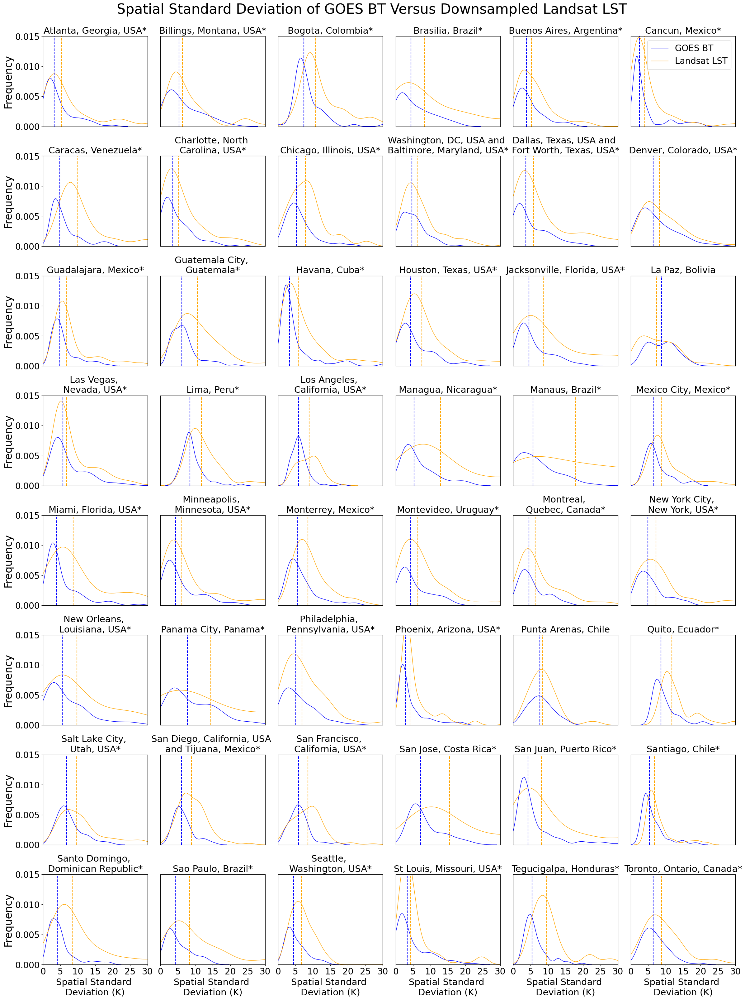

In [64]:
# Set up plot axes and general variables
fig, axs = plt.subplots(8, 6)
fig.set_size_inches(24, 32)
plt.subplots_adjust(hspace=0.2)

for i in range(8):
    print(i)
    for j in range(6):
        city = cities[i*6+j]

        # Get GOES BT spatial standard deviations and fit a PDF
        GOES_data = np.stack(get_GOES_vars(city)).flatten()
        GOES_pdf = KDEUnivariate(GOES_data)
        GOES_pdf.fit()
        BT_std = GOES_pdf.density/np.sum(GOES_pdf.density)

        # Get Landsat LST spatial standard deviations and fit a PDF
        Landsat_data = np.array(get_filtered_Landsat_vars(city))
        Landsat_pdf = KDEUnivariate(Landsat_data[~np.isnan(Landsat_data)])
        Landsat_pdf.fit()
        LST_std = Landsat_pdf.density/np.sum(Landsat_pdf.density)

        # Calculate Mann-Whitney U test for equivalence of distribution
        p_value = stats.mannwhitneyu(Landsat_data, GOES_data, alternative='greater', nan_policy='omit').pvalue

        # Plot both PDFs
        axs[i, j].plot(GOES_pdf.support, BT_std, color='b', linewidth=1, label='GOES BT')
        axs[i, j].plot(Landsat_pdf.support, LST_std, color='orange', linewidth=1, label='Landsat LST')

        # Calculate the midpoint of both distributions
        # and plot them as dashed vertical lines
        Landsat_middle = Landsat_pdf.support[np.where(Landsat_pdf.cdf >= 0.5)[0][0]]
        GOES_middle = GOES_pdf.support[np.where(GOES_pdf.cdf >= 0.5)[0][0]]
        axs[i, j].axvline(x=Landsat_middle, color='orange', linestyle='--')
        axs[i, j].axvline(x=GOES_middle, color='b', linestyle='--')

        # Set axis title, with an asterisk if p < 0.05
        if p_value < 0.05:
            axs[i, j].set_title(city_str_dict[city]+'*', fontsize=21)
        else:
            axs[i, j].set_title(city_str_dict[city], fontsize=21)

        # Format y-axis ticks to 3 decimal places
        formatter_y = mticker.StrMethodFormatter("{x:.3f}")
        axs[i, j].yaxis.set_major_formatter(formatter_y)
        axs[i, j].set_xlim(left=0, right=30)
        axs[i, j].set_xticks([])
        axs[i, j].set_ylim(bottom=0, top=0.015)
        axs[i, j].set_yticks([])

        # Set axis ticks and labels for the left and bottom edges
        if j == 0:
            axs[i, j].set_ylabel('Frequency', fontsize=24)
            axs[i, j].set_yticks(np.arange(0, 0.016, 0.005))
            axs[i, j].tick_params(axis='y', labelsize=20)
        if i == 7:
            axs[i, j].set_xlabel('Spatial Standard \nDeviation (K)', fontsize=21)
            axs[i, j].set_xticks(np.arange(0, 31, 5))
            axs[i, j].tick_params(axis='x', labelsize=20)

# Add a legend
handles, labels = axs[0, 0].get_legend_handles_labels()
axs[0, 5].legend(handles, labels, fontsize=20, loc='upper right')

# Set a title and save the figure
plt.suptitle('Spatial Standard Deviation of GOES BT Versus Downsampled Landsat LST', y=1.001, fontsize=32)
plt.tight_layout()
fig.savefig('/glade/derecho/scratch/jstarfeldt/data_analysis/plots/Filtered_spatial_variabilities.pdf', transparent=True, bbox_inches='tight')

0
1


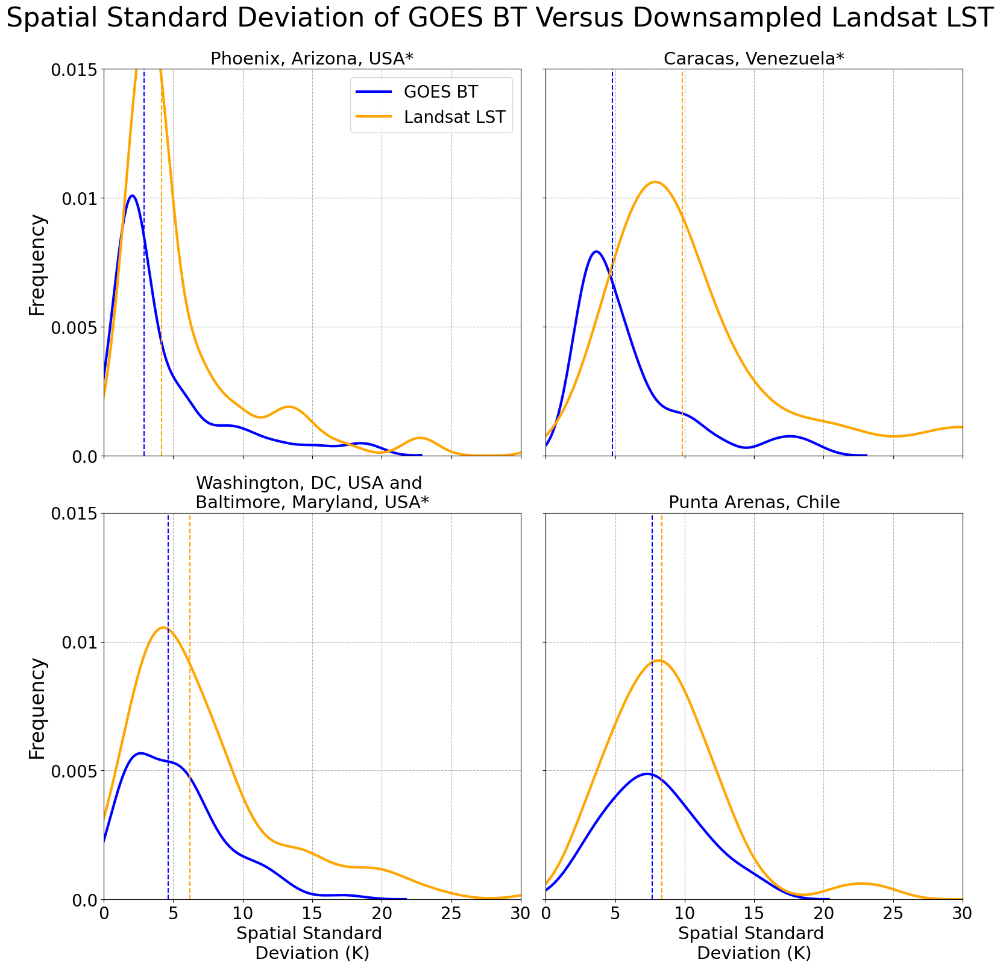

In [14]:
# Set up plot axes and general variables
fig, axs = plt.subplots(2, 2)
fig.set_size_inches(16, 16)
#plt.subplots_adjust(hspace=0.2)
select_cities = ['Phoenix', 'Caracas', 'DMV', 'Punta_Arenas']

for i in range(2):
    print(i)
    for j in range(2):
        city = select_cities[i*2+j]

        # Get GOES BT spatial standard deviations and fit a PDF
        GOES_data = np.stack(get_GOES_vars(city)).flatten()
        GOES_pdf = KDEUnivariate(GOES_data)
        GOES_pdf.fit()
        BT_std = GOES_pdf.density/np.sum(GOES_pdf.density)

        # Get Landsat LST spatial standard deviations and fit a PDF
        Landsat_data = np.array(get_filtered_Landsat_vars(city))
        Landsat_pdf = KDEUnivariate(Landsat_data[~np.isnan(Landsat_data)])
        Landsat_pdf.fit()
        LST_std = Landsat_pdf.density/np.sum(Landsat_pdf.density)

        # Calculate Mann-Whitney U test for equivalence of distribution
        p_value = stats.mannwhitneyu(Landsat_data, GOES_data, alternative='greater', nan_policy='omit').pvalue

        # Plot both PDFs
        axs[i, j].plot(GOES_pdf.support, BT_std, color='b', linewidth=3, label='GOES BT')
        axs[i, j].plot(Landsat_pdf.support, LST_std, color='orange', linewidth=3, label='Landsat LST')

        # Calculate the midpoint of both distributions
        # and plot them as dashed vertical lines
        Landsat_middle = Landsat_pdf.support[np.where(Landsat_pdf.cdf >= 0.5)[0][0]]
        GOES_middle = GOES_pdf.support[np.where(GOES_pdf.cdf >= 0.5)[0][0]]
        axs[i, j].axvline(x=Landsat_middle, color='orange', linestyle='--')
        axs[i, j].axvline(x=GOES_middle, color='b', linestyle='--')

        # Set axis title, with an asterisk if p < 0.05
        if p_value < 0.05:
            axs[i, j].set_title(city_str_dict[city]+'*', fontsize=21)
        else:
            axs[i, j].set_title(city_str_dict[city], fontsize=21)

        # Format y-axis ticks to 3 decimal places
        formatter_y = mticker.StrMethodFormatter("{x:.3f}")
        axs[i, j].yaxis.set_major_formatter(formatter_y)
        axs[i, j].set_xlim(left=0, right=30)
        axs[i, j].set_xticks(np.arange(0, 31, 5), labels=[])
        axs[i, j].set_ylim(bottom=0, top=0.015)
        axs[i, j].set_yticks(np.arange(0, 0.016, 0.005), labels=[])
        axs[i, j].grid(True, linestyle='dashed')

        # Set axis ticks and labels for the left and bottom edges
        if j == 0:
            axs[i, j].set_ylabel('Frequency', fontsize=24)
            axs[i, j].set_yticks(np.arange(0, 0.016, 0.005), labels=np.arange(0, 0.016, 0.005))
            axs[i, j].tick_params(axis='y', labelsize=20)
        if i == 1:
            axs[i, j].set_xlabel('Spatial Standard \nDeviation (K)', fontsize=21)
            axs[i, j].set_xticks(np.arange(0, 31, 5), labels=np.arange(0, 31, 5))
            axs[i, j].tick_params(axis='x', labelsize=20)

# Add a legend
handles, labels = axs[0, 0].get_legend_handles_labels()
axs[0, 0].legend(handles, labels, fontsize=20, loc='upper right')

# Set a title and save the figure
plt.suptitle('Spatial Standard Deviation of GOES BT Versus Downsampled Landsat LST', y=1.001, fontsize=32)
plt.tight_layout()
fig.savefig('/glade/derecho/scratch/jstarfeldt/data_analysis/plots/presentation_filtered_spatial_variabilities.pdf', transparent=True, bbox_inches='tight')

## Data Cube Figure

Two-panel figure is produced in the data_cubes_figure.ipynb file

In [14]:
city = 'Atlanta'

In [15]:
data = xr.open_dataset(f'{dataset_root}/lresgrid/2022/01/{city_ICAO_codes[city]}/lresgrid_{city_ICAO_codes[city]}_202201041610.nc')
data

<xarray.Dataset> Size: 82kB
Dimensions:        (y: 45, x: 45)
Coordinates:
  * y              (y) float64 360B 3.699e+06 3.701e+06 ... 3.785e+06 3.787e+06
  * x              (x) float64 360B 7.05e+05 7.07e+05 ... 7.91e+05 7.93e+05
    datetime       object 8B ...
Data variables:
    GOES_C13_LWIR  (y, x) float64 16kB ...
    GOES_C14_LWIR  (y, x) float64 16kB ...
    GOES_C15_LWIR  (y, x) float64 16kB ...
    GOES_C16_LWIR  (y, x) float64 16kB ...
    microwave_LST  (y, x) float64 16kB ...
    spatial_ref    int32 4B ...
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    title:          GOES-16 and microwave LST data for Atlanta, Georgia, USA
    institution:    University of Maryland, College Park
    source:         Satellite observation

In [16]:
acm = xr.open_dataset(f'{dataset_root}/lresgrid/cloud_mask/{city_ICAO_codes[city]}/lresgrid_{city_ICAO_codes[city]}_202201041610_mask.nc')
acm

<xarray.Dataset> Size: 17kB
Dimensions:          (y: 45, x: 45)
Coordinates:
  * y                (y) float64 360B 3.699e+06 3.701e+06 ... 3.787e+06
  * x                (x) float64 360B 7.05e+05 7.07e+05 ... 7.91e+05 7.93e+05
    spatial_ref      int32 4B ...
Data variables:
    GOES_cloud_mask  (y, x) float64 16kB ...
Attributes:
    AREA_OR_POINT:  Area
    title:          Latitude and Longitude coordinates of low-resolution grid...
    institution:    University of Maryland, College Park

In [17]:
def imshow3d(ax, array, value_direction='z', pos=0, norm=None, cmap=None):
    """
    Display a 2D array as a  color-coded 2D image embedded in 3d.

    The image will be in a plane perpendicular to the coordinate axis *value_direction*.

    Parameters
    ----------
    ax : Axes3D
        The 3D Axes to plot into.
    array : 2D numpy array
        The image values.
    value_direction : {'x', 'y', 'z'}
        The axis normal to the image plane.
    pos : float
        The numeric value on the *value_direction* axis at which the image plane is
        located.
    norm : `~matplotlib.colors.Normalize`, default: Normalize
        The normalization method used to scale scalar data. See `imshow()`.
    cmap : str or `~matplotlib.colors.Colormap`, default: :rc:`image.cmap`
        The Colormap instance or registered colormap name used to map scalar data
        to colors.
    """
    if norm is None:
        norm = Normalize()
    colors = plt.get_cmap(cmap)(norm(array))

    if value_direction == 'x':
        nz, ny = array.shape
        zi, yi = np.mgrid[0:nz + 1, 0:ny + 1]
        xi = np.full_like(yi, pos)
    elif value_direction == 'y':
        nx, nz = array.shape
        xi, zi = np.mgrid[0:nx + 1, 0:nz + 1]
        yi = np.full_like(zi, pos)
    elif value_direction == 'z':
        ny, nx = array.shape
        yi, xi = np.mgrid[0:ny + 1, 0:nx + 1]
        zi = np.full_like(xi, pos)
    else:
        raise ValueError(f"Invalid value_direction: {value_direction!r}")
    ax.plot_surface(xi, yi, zi, rstride=1, cstride=1, facecolors=colors, shade=False)

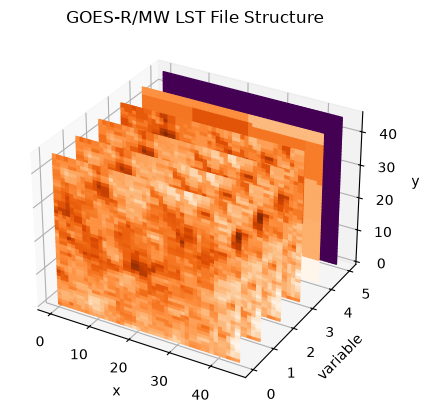

In [21]:
# Set up 3D axes
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.set(xlabel="x", ylabel="variable", zlabel="y")

# For each variable, coarsen image to 11x11 pixels before plotting in on
# the 3d axes. Coarsening is done to maintain a proportionally coarser
# resolution than the Landsat data cube figure below
vals = data['GOES_C13_LWIR'].values
imshow3d(ax, vals, value_direction='y', pos=0, cmap='Oranges')

vals = data['GOES_C14_LWIR'].values
imshow3d(ax, vals, value_direction='y', pos=1, cmap='Oranges')

vals = data['GOES_C15_LWIR'].values
imshow3d(ax, vals, value_direction='y', pos=2, cmap='Oranges')

vals = data['GOES_C16_LWIR'].values
imshow3d(ax, vals, value_direction='y', pos=3, cmap='Oranges')

vals = data['microwave_LST'].values
imshow3d(ax, vals, value_direction='y', pos=4, cmap='Oranges')

vals = acm['GOES_cloud_mask'].values
imshow3d(ax, vals, value_direction='y', pos=5)

# Set a title and save the figure
plt.title('GOES-R/MW LST File Structure')
#plt.show()
fig.savefig('/glade/derecho/scratch/jstarfeldt/data_analysis/plots/GOES_file_structure.pdf', transparent=True, bbox_inches='tight')

In [22]:
data = xr.open_dataset(f'{dataset_root}/hresgrid/2022/01/{city_ICAO_codes[city]}/hresgrid_{city_ICAO_codes[city]}_202201041612.nc')
data

<xarray.Dataset> Size: 936MB
Dimensions:                        (y: 3000, x: 3000)
Coordinates:
  * y                              (y) float64 24kB 3.698e+06 ... 3.788e+06
  * x                              (x) float64 24kB 7.031e+05 ... 7.931e+05
    datetime                       object 8B ...
Data variables: (12/14)
    Landsat_cloud_mask             (y, x) object 72MB ...
    Landsat_blue_sfc_reflectance   (y, x) float64 72MB ...
    Landsat_green_sfc_reflectance  (y, x) float64 72MB ...
    Landsat_red_sfc_reflectance    (y, x) float64 72MB ...
    Landsat_NIR_sfc_reflectance    (y, x) float64 72MB ...
    Landsat_SWIR1_sfc_reflectance  (y, x) float64 72MB ...
    ...                             ...
    Sentinel1_VV                   (y, x) float64 72MB ...
    Sentinel1_VH                   (y, x) float64 72MB ...
    Sentinel1_HH                   (y, x) float64 72MB ...
    Sentinel1_HV                   (y, x) float64 72MB ...
    Sentinel1_incidence_angle      (y, x) float64 72MB ...
    spatial_ref                    int32 4B ...
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    title:          Landsat 8 and Sentinel-1 data for Atlanta, Georgia, USA
    institution:    University of Maryland, College Park
    source:         Satellite observation

done with Landsat
done with Sentinel


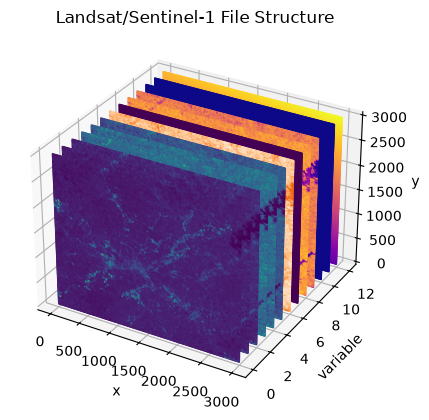

In [25]:
# Set up 3d axes
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.set(xlabel="x", ylabel="variable", zlabel="y")
#ax.set_ylabel(['G13', 'G14', 'G15', 'G16', 'MwLST'])

# For each variable coarsen image to 30x30 pixels before plotting on
# the 3d axes. Coarsening is done to limit figure storage size
vals = data['Landsat_blue_sfc_reflectance'].values
resized_blue = np.array(Image.fromarray(np.nan_to_num(vals, nan=np.nanmean(vals))).resize((200, 200)))
imshow3d(ax, resized_blue, value_direction='y', pos=0)

vals = data['Landsat_green_sfc_reflectance'].values
resized_green = np.array(Image.fromarray(np.nan_to_num(vals, nan=np.nanmean(vals))).resize((200, 200)))
imshow3d(ax, resized_green, value_direction='y', pos=1)

vals = data['Landsat_red_sfc_reflectance'].values
resized_red = np.array(Image.fromarray(np.nan_to_num(vals, nan=np.nanmean(vals))).resize((200, 200)))
imshow3d(ax, resized_red, value_direction='y', pos=2)

vals = data['Landsat_NIR_sfc_reflectance'].values
resized_NIR = np.array(Image.fromarray(np.nan_to_num(vals, nan=np.nanmean(vals))).resize((200, 200)))
imshow3d(ax, resized_NIR, value_direction='y', pos=3)

vals = data['Landsat_SWIR1_sfc_reflectance'].values
resized_SWIR1 = np.array(Image.fromarray(np.nan_to_num(vals, nan=np.nanmean(vals))).resize((200, 200)))
imshow3d(ax, resized_SWIR1, value_direction='y', pos=4)

vals = data['Landsat_SWIR2_sfc_reflectance'].values
resized_SWIR2 = np.array(Image.fromarray(np.nan_to_num(vals, nan=np.nanmean(vals))).resize((200, 200)))
imshow3d(ax, resized_SWIR2, value_direction='y', pos=5)

vals = data['Landsat_LST'].values
resized_LST = np.array(Image.fromarray(np.nan_to_num(vals, nan=np.nanmean(vals))).resize((200, 200)))
imshow3d(ax, resized_LST, value_direction='y', pos=6, cmap='Oranges')

resized_cloud = np.array(Image.fromarray(cloud_func(data['Landsat_cloud_mask'].values) == '1').resize((200, 200)))
imshow3d(ax, resized_cloud, value_direction='y', pos=7)
print('done with Landsat')

vals = data['Sentinel1_VV'].values
resized_VV = np.array(Image.fromarray(np.nan_to_num(vals, nan=np.nanmean(vals))).resize((200, 200)))
imshow3d(ax, resized_VV, value_direction='y', pos=8, cmap='plasma')

vals = data['Sentinel1_VH'].values
resized_VH = np.array(Image.fromarray(np.nan_to_num(vals, nan=np.nanmean(vals))).resize((200, 200)))
imshow3d(ax, resized_VH, value_direction='y', pos=9, cmap='plasma')

resized_HH = np.zeros((200, 200))
imshow3d(ax, resized_HH, value_direction='y', pos=10, cmap='plasma')

resized_HV = np.zeros((200, 200))
imshow3d(ax, resized_HV, value_direction='y', pos=11, cmap='plasma')

vals = data['Sentinel1_incidence_angle'].values
resized_angle = np.array(Image.fromarray(np.nan_to_num(vals, nan=np.nanmean(vals))).resize((200, 200)))
imshow3d(ax, resized_angle, value_direction='y', pos=12, cmap='plasma')
print('done with Sentinel')

# Add original data dimensions for figure purposes
ax.set_xticks([0, 33, 67, 100, 133, 167, 200])
ax.set_zticks([0, 33, 67, 100, 133, 167, 200])
ax.set_xticklabels(np.arange(0, 3001, 500))
ax.set_zticklabels(np.arange(0, 3001, 500))

# Set a title and save the figure
plt.title('Landsat/Sentinel-1 File Structure')
#plt.show()
fig.savefig('/glade/derecho/scratch/jstarfeldt/data_analysis/plots/Landsat_file_structure.pdf', transparent=True, bbox_inches='tight')